# Predicción de deforestación con TransUNet++ (segmentación + clasificación por parche)
**MIA-203 Redes Neuronales y Aprendizaje Profundo — UNI FIIS · Examen Final**

Dataset: `Dataset_deforestacion` (Kaggle, carpeta `unet_dataset`), con arreglos NumPy por partición:
`*_X.npy` (parches de 37 capas geoespaciales: pérdida histórica, bosque, lluvia, topografía, protección, accesibilidad OSM/MTC y MapBiomas), `*_Y.npy` (máscara de pérdida de bosque), `*_M.npy` (máscara de píxeles válidos), además de `meta.json`, `normalizacion.npz` y `muestras.csv`.

**Planteamiento.** Se entrena una **TransUNet++**, que combina dos ideas: (i) de **TransUNet** (Chen et al., 2021), un encoder convolucional cuyo *bottleneck* pasa por un **Transformer** (auto-atención multi-cabeza sobre los *tokens* espaciales) para modelar **contexto global** del parche; y (ii) de **UNet++** (Zhou et al., 2018), un decoder con ***skip connections* anidadas y densas** y **supervisión profunda**, que reducen la brecha semántica entre encoder y decoder. La red produce el **mapa de pérdida píxel a píxel** a partir de todas las capas de entrada (bosque, lluvia, topografía, accesibilidad, MapBiomas…), y una cabeza auxiliar sobre el *bottleneck* clasifica el parche: *deforestación* si la fracción de píxeles válidos con pérdida supera `FRAC_THRESHOLD`. Se generan las **predicciones sobre `val`**.

| Requisito | Dónde se cubre |
|---|---|
| **R1** Fundamento en el curso | §4 CNN + Transformer (auto-atención multi-cabeza) + decoder anidado con supervisión profunda; pérdida multitarea (BCE + Dice + CE) formulada |
| **R2** Originalidad | Datos de deforestación del Perú con capas geoespaciales multifuente; arquitectura híbrida CNN-Transformer con decoder anidado; modelo multitarea segmentación + clasificación |
| **R3** Línea base | §8 Random Forest y regresión logística con estadísticos por banda |
| **R4** Experimentación | §9 Ablaciones con varias semillas (media ± d.e.): Transformer, *skips* anidados, supervisión profunda, número de capas de atención, pérdida de segmentación, aumentos |
| **R5** Interpretación | §10 Mapas de TransUNet++ y Grad-CAM vs. máscara real (pointing game, IoU), prueba de borrado, calibración, t-SNE, errores vs. fracción de pérdida |
| **R6** Costo y responsabilidad | §11 Hardware, horas de GPU, energía y CO₂; §13 limitaciones, sesgos y riesgos |

> **Sin fuga de datos.** `val` y `test` del dataset **nunca** se usan para decidir épocas, hiperparámetros ni variantes. La selección de modelo usa una **validación interna** extraída de `train`.

**En Kaggle** (*Settings*): **Accelerator → GPU T4**. La red se entrena desde cero (no requiere Internet). Las salidas quedan en `/kaggle/working`.

## 0. Parámetros
Todo es configurable (`EPOCHS` = 10 por defecto). La celda tiene la etiqueta `parameters` (compatible con papermill).

In [1]:
from pathlib import Path

# ===================== PARÁMETROS =====================
DATA_DIR = Path("/kaggle/input/datasets/gerardobarzola/dataset-deforestacion/unet_dataset")

# --- Arquitectura: TransUNet++ ---
BASE_CH       = 32          # canales del encoder CNN por nivel (32 → 64 → 128 → 256 → 512)
DEPTH         = 4           # número de reducciones; el parche se rellena a múltiplo de 2**DEPTH
TRANS_LAYERS  = 4           # capas Transformer en el bottleneck (0 = sin Transformer)
EMBED_DIM     = 256         # dimensión de los tokens del Transformer
N_HEADS       = 8           # cabezas de auto-atención
TRANS_DROPOUT = 0.1
NESTED_SKIPS  = True        # skips anidados y densos (UNet++); False = skips simples
DEEP_SUPERVISION = True     # una cabeza de segmentación por cada nodo X^{0,j} (promediadas)
USE_DICE      = True        # añadir el término Dice a la BCE de segmentación
SEG_LOSS_WEIGHT = 1.0       # peso de la pérdida de segmentación frente a la de clasificación
GRAD_CLIP     = 1.0         # recorte de la norma del gradiente (estabiliza el Transformer)

# --- Modelo principal ---
EPOCHS          = 10        # número de épocas (configurable)
BATCH_SIZE      = 32
LR              = 1e-3
WEIGHT_DECAY    = 1e-4
LABEL_SMOOTHING = 0.1
DROPOUT         = 0.3
WARMUP_EPOCHS   = 1
PATIENCE        = 5         # early stopping sobre F1-macro (por parche) de la validación interna
AUGMENT         = True
USE_CLASS_WEIGHTS = True
SEED            = 42

# --- Etiqueta por parche (a partir de la máscara Y) ---
FRAC_THRESHOLD    = 0.05    # parche = "deforestacion" si (píxeles con pérdida / píxeles válidos) >= umbral
MASK_POSITIVE_MIN = 0.5     # un píxel de Y cuenta como pérdida si Y > este valor
USE_VALID_MASK    = True    # usar *_M.npy como máscara de píxeles válidos

# --- Bandas ---
USE_ALL_BANDS = True        # True: usa todas las bandas; False: solo RGB
RGB_IDX       = None        # índices de [R, G, B] en X, p. ej. [2, 1, 0]; None = autodetectar (meta.json / normalizacion.npz)
EXCLUDE_BAND_PATTERNS = ["pérdida", "perdida", "loss"]   # bandas que NO entran al modelo (evita fuga si X contiene la propia etiqueta); [] = usar todas
DISPLAY_BAND  = None        # banda para visualizar parches si no hay RGB (None = "bosque remanente" si existe)

# --- Particiones y experimentos ---
INTERNAL_VAL_FRACTION = 0.15
GROUP_INTERNAL_VAL    = True   # validación interna agrupada por ubicación (muestras.csv): las copias aumentadas de un parche no se reparten entre train y val interna
GROUP_BLOCK_PX        = 256    # tamaño del bloque espacial (en píxeles de la grilla fila/col) para agrupar parches vecinos
REMOVE_DUPLICATES     = True
RUN_BASELINES   = True
RUN_ABLATIONS   = True
ABLATION_EPOCHS = 5
ABLATION_SEEDS  = [42, 123, 2024]   # reduce a [42] si falta tiempo de GPU
GRADCAM_FIDELITY_SAMPLES = 64
GRADCAM_LOC_SAMPLES      = 200

# --- Costo computacional ---
GPU_POWER_W         = 70     # TDP NVIDIA T4 (W)
GRID_KG_CO2_PER_KWH = 0.25   # factor de emisión; ajústalo y cita la fuente

NUM_WORKERS = 2
WORK_DIR    = "/kaggle/working"
OUT_DIR     = "results"
CKPT_DIR    = "checkpoints"

## 1. Entorno, semillas y utilidades

In [2]:
CONFIG = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()
          if k.isupper() and isinstance(v, (int, float, str, bool, list, type(None), Path))}

import os, sys, json, time, copy, math, random, hashlib, platform, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, matthews_corrcoef, cohen_kappa_score,
                             confusion_matrix, classification_report, roc_curve, precision_recall_curve,
                             average_precision_score)

warnings.filterwarnings("ignore", category=UserWarning)
_trapz = getattr(np, "trapezoid", None) or np.trapz

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(SEED)

WORK = Path(WORK_DIR) if Path(WORK_DIR).exists() else Path.cwd()
os.chdir(WORK)
IN_KAGGLE = Path("/kaggle/input").exists()
OUT = WORK / OUT_DIR
CKPT_DIR = WORK / CKPT_DIR
for sub in ["figures", "tables", "logs"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)
(OUT / "config.json").write_text(json.dumps(CONFIG, indent=2, ensure_ascii=False))

COMPUTE_LOG = []
def log_compute(stage, group, seconds):
    COMPUTE_LOG.append(dict(etapa=stage, grupo=group, segundos=seconds, dispositivo=str(DEVICE)))

def savefig(name):
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=300, bbox_inches="tight")

def save_table(df, name, index=False):
    df.to_csv(OUT / "tables" / f"{name}.csv", index=index)
    try:
        (OUT / "tables" / f"{name}.tex").write_text(df.to_latex(index=index, float_format="%.4f"))
    except Exception:
        pass

print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print("Entorno:", "Kaggle" if IN_KAGGLE else "local", "| salida en", WORK)
print("Dispositivo:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "sin GPU (será lento)")

Python 3.13.16 | PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Entorno: Kaggle | salida en /kaggle/working
Dispositivo: cuda | Tesla T4


## 2. Dataset: archivos e inspección
Se leen los `.npy` con `mmap_mode="r"` (no se cargan completos en RAM). La celda muestra forma, tipo y rango de cada arreglo, el contenido de `meta.json`, `normalizacion.npz` y `muestras.csv`.

In [3]:
DATA_DIR = Path(DATA_DIR)
if not (DATA_DIR / "train_X.npy").exists():
    # respaldo: buscar la carpeta que contiene train_X.npy (siguiendo enlaces simbólicos de Kaggle)
    hits = [Path(d) for d, _, f in os.walk("/kaggle/input" if IN_KAGGLE else ".", followlinks=True) if "train_X.npy" in f]
    assert hits, f"No se encontró train_X.npy en {DATA_DIR}. Revisa la ruta en el panel Input."
    DATA_DIR = sorted(hits, key=lambda p: len(p.parts))[0]
print("Datos en:", DATA_DIR)
for p in sorted(DATA_DIR.iterdir()):
    print(f"   {p.name:22s} {p.stat().st_size / 1e6:10.1f} MB")
extra = [p for p in DATA_DIR.parent.iterdir() if p.is_file()]
for p in extra:
    print(f"   ../{p.name:19s} {p.stat().st_size / 1e6:10.1f} MB")

def load_npy(path):
    try:
        return np.load(path, mmap_mode="r")
    except ValueError:
        return np.load(path, allow_pickle=True)

FILES = {p.name.lower(): p for p in DATA_DIR.iterdir()}
def npy_path(split, kind):
    return FILES.get(f"{split}_{kind}.npy".lower())

SPLITS = [s for s in ("train", "val", "test") if npy_path(s, "x") is not None]
print("\nParticiones:", SPLITS)

rows = []
for s in SPLITS:
    for k in ("x", "y", "m"):
        p = npy_path(s, k)
        if p is None: continue
        a = load_npy(p)
        smp = np.asarray(a[:min(len(a), 32)], dtype=np.float64)
        u = np.unique(smp[np.isfinite(smp)])
        rows.append(dict(archivo=p.name, forma=str(a.shape), dtype=str(a.dtype), min=np.nanmin(smp), max=np.nanmax(smp),
                         media=np.nanmean(smp), nan=int(np.isnan(smp).sum()),
                         valores_unicos=str(u[:6]) if u.size <= 6 else f"{u.size}+ valores"))
inspect_df = pd.DataFrame(rows); display(inspect_df); save_table(inspect_df, "inspeccion_arreglos")

META = {}
if (DATA_DIR / "meta.json").exists():
    META = json.load(open(DATA_DIR / "meta.json"))
    for k, v in META.items():
        if isinstance(v, list) and v and isinstance(v[0], dict):
            print(f"meta.json → {k} ({len(v)} elementos):"); display(pd.DataFrame(v))
        else:
            print(f"meta.json → {k}: {json.dumps(v, ensure_ascii=False)[:600]}")
NPZ_INFO = {}
if (DATA_DIR / "normalizacion.npz").exists():
    z = np.load(DATA_DIR / "normalizacion.npz", allow_pickle=True)
    print("\nnormalizacion.npz:")
    for k in z.files:
        v = z[k]
        if v.dtype.kind in "iufb":
            print(f"   {k}: forma={v.shape} valores={np.round(v.ravel()[:10].astype(float), 4).tolist()}")
        else:
            vals = [str(t) for t in v.ravel().tolist()]
            NPZ_INFO[k] = vals                    # p. ej. nombres de bandas
            print(f"   {k}: forma={v.shape} valores={vals[:20]}")
if (DATA_DIR / "muestras.csv").exists():
    MUESTRAS = pd.read_csv(DATA_DIR / "muestras.csv"); print("\nmuestras.csv:", MUESTRAS.shape); display(MUESTRAS.head())
for p in list(DATA_DIR.glob("*.npy")) + list(DATA_DIR.parent.glob("*.npy")):
    if p.name.lower().startswith(("train_", "val_", "test_")): continue
    a = load_npy(p)
    sub = np.asarray(a[tuple(slice(None, None, max(1, n // 200)) for n in a.shape)], dtype=np.float64)  # submuestra, en float64
    print(f"\n{p.name}: forma={a.shape} dtype={a.dtype} min={np.nanmin(sub):.4g} max={np.nanmax(sub):.4g} media≈{np.nanmean(sub):.4g}")

Datos en: /kaggle/input/datasets/gerardobarzola/dataset-deforestacion/unet_dataset
   meta.json                     0.0 MB
   muestras.csv                  1.2 MB
   normalizacion.npz             0.0 MB
   test_M.npy                   23.0 MB
   test_X.npy                 1699.8 MB
   test_Y.npy                   23.0 MB
   train_M.npy                 157.3 MB
   train_X.npy               11639.2 MB
   train_Y.npy                 157.3 MB
   val_M.npy                    23.0 MB
   val_X.npy                  1699.8 MB
   val_Y.npy                    23.0 MB
   ../perdida_frac.npy        1414.3 MB

Particiones: ['train', 'val', 'test']


,archivo,forma,dtype,min,max,media,nan,valores_unicos
0,train_X.npy,"(9600, 37, 128, 128)",float16,-5.312500,51.53125,-0.201496,0,19552+ valores
1,train_Y.npy,"(9600, 1, 128, 128)",uint8,0.000000,1.00000,0.094206,0,[0. 1.]
2,train_M.npy,"(9600, 1, 128, 128)",uint8,0.000000,1.00000,0.916304,0,[0. 1.]
3,val_X.npy,"(1402, 37, 128, 128)",float16,-2.949219,47.37500,0.172364,0,17558+ valores
4,val_Y.npy,"(1402, 1, 128, 128)",uint8,0.000000,1.00000,0.003040,0,[0. 1.]
5,val_M.npy,"(1402, 1, 128, 128)",uint8,0.000000,1.00000,0.784803,0,[0. 1.]
6,test_X.npy,"(1402, 37, 128, 128)",float16,-2.949219,29.62500,0.219434,0,17668+ valores
7,test_Y.npy,"(1402, 1, 128, 128)",uint8,0.000000,1.00000,0.003307,0,[0. 1.]
8,test_M.npy,"(1402, 1, 128, 128)",uint8,0.000000,1.00000,0.784777,0,[0. 1.]


meta.json → canales (37 elementos):


,indice,nombre,grupo,tipo
0,0,pérdida t,pérdida,continuo
1,1,pérdida reciente,pérdida,continuo
2,2,pérdida acumulada,pérdida,continuo
3,3,log dist. pérdida reciente,pérdida,logdist
4,4,log dist. pérdida acumulada,pérdida,logdist
5,5,densidad pérdida reciente,pérdida,continuo
6,6,bosque 2000,bosque,continuo
7,7,bosque remanente t,bosque,continuo
8,8,anomalía Q1,lluvia,continuo
9,9,anomalía Q2,lluvia,continuo


meta.json → in_channels: 37
meta.json → patch: 128
meta.json → splits: {"train": [2015, 2016, 2017, 2018, 2019, 2020], "val": [2021, 2022], "test": [2023, 2024]}
meta.json → n_parches: {"train": 9600, "val": 1402, "test": 1402}
meta.json → copias_train: 2
meta.json → grilla: {"res_grados": 0.0025, "filas": 5979, "columnas": 4731, "oeste": -80.4795324064289, "norte": -0.03889509508897436, "crs": "EPSG:4326"}
meta.json → formato: {"X": "float16 normalizado (C,128,128)", "Y": "uint8 pérdida en t+1", "M": "uint8 celdas que cuentan en la pérdida"}

normalizacion.npz:
   MU: forma=(37,) valores=[0.0018, 0.0052, 0.0244, 2.2086, 1.7877, 0.0054, 0.7958, 0.7714, 11.2082, 10.4582]
   SD: forma=(37,) valores=[0.0194, 0.0368, 0.1033, 1.309, 1.3464, 0.0143, 0.3763, 0.386, 152.3919, 110.9578]
   nombres: forma=(37,) valores=['pérdida t', 'pérdida reciente', 'pérdida acumulada', 'log dist. pérdida reciente', 'log dist. pérdida acumulada', 'densidad pérdida reciente', 'bosque 2000', 'bosque remanente t

,split,t,fila,col,origen,prev_parche,lon,lat,zona_reservada,copia,aumentada,indice
0,train,2015,4428,4305,cerca de pérdida,NaN,-69.715782,-11.110145,False,0,False,0
1,train,2015,3424,2414,cerca de pérdida,NaN,-74.443282,-8.600145,False,0,False,1
2,train,2015,3934,1967,cerca de pérdida,NaN,-75.560782,-9.875145,False,0,False,2
3,train,2015,3408,1945,cerca de pérdida,NaN,-75.615782,-8.560145,False,0,False,3
4,train,2015,2894,1678,cerca de pérdida,NaN,-76.283282,-7.275145,False,0,False,4



perdida_frac.npy: forma=(25, 5979, 4731) dtype=float16 min=0 max=1 media≈0.0006225


## 3. Estructura, etiquetas por parche, particiones y control de fuga
**Etiqueta por parche.** Para el parche $n$ con máscara de pérdida $Y_n$ y máscara de validez $M_n$:
$$f_n = \frac{\sum_{i,j} \mathbb{1}[Y_{n,ij} > 0.5]\, M_{n,ij}}{\max\!\big(1, \sum_{i,j} M_{n,ij}\big)}, \qquad y_n = \mathbb{1}[f_n \ge \tau],$$
con $\tau$ = `FRAC_THRESHOLD`. Si `Y` resultara ser una etiqueta por parche (no una máscara), se usa directamente.

| Partición | Origen | Uso |
|---|---|---|
| `train` | `train_*.npy` (85 %) | ajustar pesos |
| `val interna` | `train_*.npy` (15 %, estratificado) | early stopping y elección de variante |
| **`val`** | `val_*.npy` | **predicciones y métricas principales** |
| `test` | `test_*.npy` | evaluación adicional |

In [4]:
X0 = load_npy(npy_path("train", "x"))
def infer_layout(shape):
    if len(shape) == 3: return "NHW"
    a, b, c = shape[1:]
    if c < a and c < b: return "NHWC"
    if a < b and a < c: return "NCHW"
    return "NHWC"
LAYOUT = infer_layout(X0.shape)
if LAYOUT == "NHWC": H, W, C = X0.shape[1:]
elif LAYOUT == "NCHW": C, H, W = X0.shape[1:]
else: (H, W), C = X0.shape[1:], 1
print(f"Disposición de X: {LAYOUT} | parches {H}x{W} | {C} banda(s)")

# --- nombres de bandas e índices RGB / NIR desde meta.json ---
def find_band_names(obj, n, need_key=True):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if isinstance(v, list) and len(v) == n and all(isinstance(t, str) for t in v) and \
               (not need_key or any(w in k.lower() for w in ("band", "canal", "channel"))):
                return v
        for v in obj.values():
            r = find_band_names(v, n, need_key)
            if r: return r
    elif isinstance(obj, list):
        for v in obj:
            r = find_band_names(v, n, need_key)
            if r: return r
    return None
BAND_GROUPS = None
for v in META.values():
    if isinstance(v, list) and len(v) == C and all(isinstance(t, dict) and "nombre" in t for t in v):
        v = sorted(v, key=lambda t: t.get("indice", 0))
        META_NAMES = [str(t["nombre"]) for t in v]; BAND_GROUPS = [str(t.get("grupo", "otro")) for t in v]
        break
else:
    META_NAMES = None
BAND_NAMES = (META_NAMES or find_band_names(META, C) or find_band_names(NPZ_INFO, C) or find_band_names(META, C, need_key=False)
              or find_band_names(NPZ_INFO, C, need_key=False) or [f"banda_{i}" for i in range(C)])
BAND_NAMES = [str(b) for b in BAND_NAMES]
EXCLUDED = [i for i, n in enumerate(BAND_NAMES) if any(p.lower() in n.lower() for p in EXCLUDE_BAND_PATTERNS)]
if EXCLUDED:
    print("ATENCIÓN: se EXCLUYEN de la entrada las bandas", [BAND_NAMES[i] for i in EXCLUDED],
          "porque su nombre sugiere que contienen la pérdida de bosque (la etiqueta) → evitaría fuga de datos.",
          "Si es información histórica legítima (p. ej. pérdida en un año anterior), pon EXCLUDE_BAND_PATTERNS = [].")

def band_idx(words, codes):
    for i, n in enumerate(BAND_NAMES):
        if i in EXCLUDED: continue
        t = n.lower().replace(" ", "").replace("_", "")
        if any(w in t for w in words) or t in codes or any(t.endswith(c) for c in codes if len(c) > 1):
            return i
    return None
auto_rgb = [band_idx(("red", "rojo"), ("r", "b4", "srb4")),
            band_idx(("green", "verde"), ("g", "b3", "srb3")),
            band_idx(("blue", "azul"), ("b", "b2", "srb2"))]
NIR_IDX = band_idx(("nir", "infrarrojo"), ("b8", "b8a"))
_RGB_USER = RGB_IDX is not None
if RGB_IDX is None:
    if None not in auto_rgb and len(set(auto_rgb)) == 3:
        RGB_IDX = auto_rgb
    else:
        usable = [c for c in range(C) if c not in EXCLUDED]
        RGB_IDX = usable[:3] if len(usable) >= 3 else [usable[0]] * 3
        pass   # sin RGB: se visualiza una banda (DISPLAY_BAND)
CH_ORDER = (list(dict.fromkeys(RGB_IDX)) + [c for c in range(C) if c not in RGB_IDX]) if USE_ALL_BANDS else list(RGB_IDX)
CH_ORDER = [c for c in CH_ORDER if c not in EXCLUDED]
if C < 3: CH_ORDER = [c for c in range(C) if c not in EXCLUDED]
assert CH_ORDER, "Todas las bandas quedaron excluidas; revisa EXCLUDE_BAND_PATTERNS."
C_IN = len(CH_ORDER)
RGB_FOUND = _RGB_USER or (None not in auto_rgb and len(set(auto_rgb)) == 3)
if DISPLAY_BAND is None:
    cand = [i for i, n in enumerate(BAND_NAMES) if "bosque remanente" in n.lower()] or [CH_ORDER[0]]
    DISPLAY_IDX = cand[0]
else:
    DISPLAY_IDX = DISPLAY_BAND if isinstance(DISPLAY_BAND, int) else BAND_NAMES.index(DISPLAY_BAND)
if BAND_GROUPS is None:
    BAND_GROUPS = ["otro"] * C
print("Bandas:", BAND_NAMES)
print("Grupos:", dict(Counter(BAND_GROUPS)))
print("RGB:", [BAND_NAMES[i] for i in RGB_IDX] if RGB_FOUND else "no hay bandas RGB → se visualiza " + repr(BAND_NAMES[DISPLAY_IDX]),
      "| NIR =", BAND_NAMES[NIR_IDX] if NIR_IDX is not None else "no")
print("Orden de entrada a la red:", [BAND_NAMES[i] for i in CH_ORDER], f"({C_IN} canales)")

def to_hw(a):
    a = np.asarray(a)
    if a.ndim == 4:
        if a.shape[1] == 1: a = a[:, 0]
        elif a.shape[-1] == 1: a = a[..., 0]
        elif a.shape[1] < a.shape[-1]: a = a.argmax(1)
        else: a = a.argmax(-1)
    return a.astype(np.float32)

def split_targets(split):
    n = len(load_npy(npy_path(split, "x")))
    yp, mp = npy_path(split, "y"), npy_path(split, "m")
    Y = load_npy(yp) if yp else None
    M = load_npy(mp) if (mp and USE_VALID_MASK) else None
    is_mask = Y is not None and Y.ndim >= 3 and to_hw(Y[:1]).shape[1:] == (H, W)
    if M is not None and not (M.ndim >= 3 and to_hw(M[:1]).shape[1:] == (H, W)):
        print(f"[{split}] M no tiene forma de máscara {H}x{W}; se ignora."); M = None
    frac, valid = np.full(n, np.nan), np.ones(n)
    if is_mask:
        for i0 in range(0, n, 256):
            y = to_hw(Y[i0:i0 + 256]) > MASK_POSITIVE_MIN
            m = (to_hw(M[i0:i0 + 256]) > 0.5) if M is not None else np.ones_like(y)
            frac[i0:i0 + 256] = (y & m).sum((1, 2)) / np.maximum(m.sum((1, 2)), 1)
            valid[i0:i0 + 256] = m.mean((1, 2))
        return dict(kind="mascara", frac=frac, valid=valid)
    y = np.asarray(Y)
    y = y.argmax(1) if y.ndim == 2 and y.shape[1] > 1 else y.reshape(n)
    if np.allclose(y, np.round(y)):
        return dict(kind="clase", labels=y.astype(int), frac=frac, valid=valid)
    return dict(kind="fraccion", frac=y.astype(float), valid=valid)

TGT = {s: split_targets(s) for s in SPLITS}
Y_KIND = TGT["train"]["kind"]
print("Tipo de Y:", Y_KIND)
if Y_KIND == "clase":
    vals = sorted(set(np.concatenate([TGT[s]["labels"] for s in SPLITS]).tolist()))
    CLASSES = [str(META.get("clases", {}).get(str(v), f"clase_{v}")) if isinstance(META.get("clases"), dict) else f"clase_{v}" for v in vals]
    LAB = {s: np.searchsorted(vals, TGT[s]["labels"]) for s in SPLITS}
else:
    CLASSES = ["sin_deforestacion", "deforestacion"]
    LAB = {s: (TGT[s]["frac"] >= FRAC_THRESHOLD).astype(int) for s in SPLITS}
FRAC = {s: TGT[s]["frac"] for s in SPLITS}
VALID = {s: TGT[s]["valid"] for s in SPLITS}
K = len(CLASSES); CLS2IDX = {c: i for i, c in enumerate(CLASSES)}

def samples_of(split):
    return [(split, i, int(LAB[split][i])) for i in range(len(LAB[split]))]

full_train = samples_of("train")
labels_tr = [s[2] for s in full_train]
GROUPS = None
mpath = DATA_DIR / "muestras.csv"
if GROUP_INTERNAL_VAL and mpath.exists():
    mu = pd.read_csv(mpath)
    if {"split", "indice", "fila", "col"} <= set(mu.columns):
        mt = mu[mu.split == "train"].set_index("indice")
        if len(mt) == len(full_train):
            GROUPS = ((mt.loc[[t[1] for t in full_train], "fila"].values // GROUP_BLOCK_PX).astype(int) * 100000 +
                      (mt.loc[[t[1] for t in full_train], "col"].values // GROUP_BLOCK_PX).astype(int))
            if "aumentada" in mt.columns:
                print(f"Parches aumentados en train: {int(mt.aumentada.sum())} de {len(mt)}")
if GROUPS is not None:
    from sklearn.model_selection import StratifiedGroupKFold
    sgk = StratifiedGroupKFold(n_splits=max(2, round(1 / INTERNAL_VAL_FRACTION)), shuffle=True, random_state=SEED)
    tr_i, iv_i = next(sgk.split(np.zeros(len(full_train)), labels_tr, GROUPS))
    train_s, ival_s = [full_train[i] for i in tr_i], [full_train[i] for i in iv_i]
    print(f"Validación interna AGRUPADA por bloques de {GROUP_BLOCK_PX} px: {len(set(GROUPS))} grupos; "
          f"ningún bloque (ni sus copias aumentadas) está a la vez en train y en val interna.")
else:
    strat = labels_tr if min(Counter(labels_tr).values()) >= 2 else None
    train_s, ival_s = train_test_split(full_train, test_size=INTERNAL_VAL_FRACTION, random_state=SEED, stratify=strat)
    print("Validación interna aleatoria estratificada (sin información de ubicación).")
HOLDOUT_NAME = "val" if "val" in SPLITS else "test"
holdout    = samples_of(HOLDOUT_NAME)
extra_test = samples_of("test") if ("test" in SPLITS and HOLDOUT_NAME == "val") else []
print(f"Clases: {CLASSES}")
print(f"train={len(train_s)} | val interna={len(ival_s)} | {HOLDOUT_NAME}={len(holdout)} | test={len(extra_test)}")

Disposición de X: NCHW | parches 128x128 | 37 banda(s)
ATENCIÓN: se EXCLUYEN de la entrada las bandas ['pérdida t', 'pérdida reciente', 'pérdida acumulada', 'log dist. pérdida reciente', 'log dist. pérdida acumulada', 'densidad pérdida reciente'] porque su nombre sugiere que contienen la pérdida de bosque (la etiqueta) → evitaría fuga de datos. Si es información histórica legítima (p. ej. pérdida en un año anterior), pon EXCLUDE_BAND_PATTERNS = [].
Bandas: ['pérdida t', 'pérdida reciente', 'pérdida acumulada', 'log dist. pérdida reciente', 'log dist. pérdida acumulada', 'densidad pérdida reciente', 'bosque 2000', 'bosque remanente t', 'anomalía Q1', 'anomalía Q2', 'anomalía Q3', 'anomalía Q4', 'anomalía anual', 'climatología Q1', 'climatología Q2', 'climatología Q3', 'climatología Q4', 'climatología anual', 'elevación', 'pendiente', 'nivel de protección t', 'dist. firmada a ANP t', 'zona de amortiguamiento', 'log dist. vías principales (OSM)', 'log dist. trochas y vías menores (OSM)', 

In [5]:
# ---- Control de fuga: parches idénticos entre particiones (hash MD5 del arreglo) ----
_MM = {}
def arr(split, kind="x"):
    key = (os.getpid(), split, kind)       # un mmap por proceso (compatible con DataLoader multiproceso)
    if key not in _MM:
        _MM[key] = load_npy(npy_path(split, kind))
    return _MM[key]

t0 = time.time()
HASH = {}
for s in SPLITS:
    A = arr(s)
    for i in range(len(A)):
        HASH[(s, i)] = hashlib.md5(np.ascontiguousarray(A[i]).tobytes()).hexdigest()
h_hold = {HASH[(s, i)] for s, i, _ in holdout + extra_test}
h_ival = {HASH[(s, i)] for s, i, _ in ival_s}
d1 = sum(HASH[(s, i)] in h_hold for s, i, _ in train_s)
d2 = sum(HASH[(s, i)] in h_ival for s, i, _ in train_s)
d3 = sum(HASH[(s, i)] in h_hold for s, i, _ in ival_s)
print(f"Duplicados exactos  train∩val/test: {d1} | train∩val_interna: {d2} | val_interna∩val/test: {d3}")
if REMOVE_DUPLICATES and d1 + d2 + d3:
    train_s = [t for t in train_s if HASH[t[:2]] not in h_hold and HASH[t[:2]] not in h_ival]
    ival_s  = [t for t in ival_s if HASH[t[:2]] not in h_hold]
    print(f"Tras eliminar duplicados: train={len(train_s)} | val interna={len(ival_s)}")
save_table(pd.DataFrame([dict(par="train ∩ val/test", duplicados=d1), dict(par="train ∩ val interna", duplicados=d2),
                         dict(par="val interna ∩ val/test", duplicados=d3)]), "control_fuga_duplicados")
print(f"(hash en {time.time() - t0:.1f}s)")

Duplicados exactos  train∩val/test: 0 | train∩val_interna: 0 | val_interna∩val/test: 0
(hash en 63.6s)


### 3.1 Normalización y análisis exploratorio
Cada banda se estandariza con media y desviación estándar calculadas **solo con `train`** (los NaN se reemplazan por 0 tras estandarizar).

,banda,media,std,p02,p98
0,pérdida t,0.2041,1.7681,-0.0906,4.0391
1,pérdida reciente,0.3258,1.7969,-0.1427,5.8359
2,pérdida acumulada,0.5157,1.7258,-0.2362,6.9258
3,log dist. pérdida reciente,-0.5913,0.7428,-1.6875,0.9810
4,log dist. pérdida acumulada,-0.5535,0.6561,-1.3281,0.8652
5,densidad pérdida reciente,0.8265,1.8505,-0.3735,6.5781
6,bosque 2000,0.1296,0.7933,-2.1152,0.5425
7,bosque remanente t,-0.0101,0.8840,-1.9980,0.5923
8,anomalía Q1,0.1624,1.4102,-2.8926,3.9004
9,anomalía Q2,0.1305,1.2598,-2.2910,3.2969


,train,val interna,val,test
sin_deforestacion,3998,624,1105,1160
deforestacion,4668,310,297,242
TOTAL,8666,934,1402,1402


Razón de desbalance en train: 1.17
Cuantiles 50/75/90/95 % de la fracción: [0.0545 0.1176 0.1669 0.1953] | parches con alguna pérdida: 98.5%


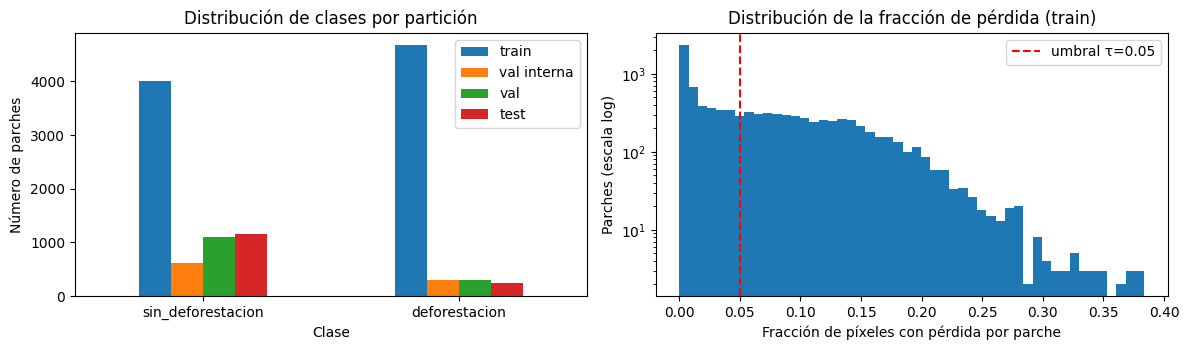

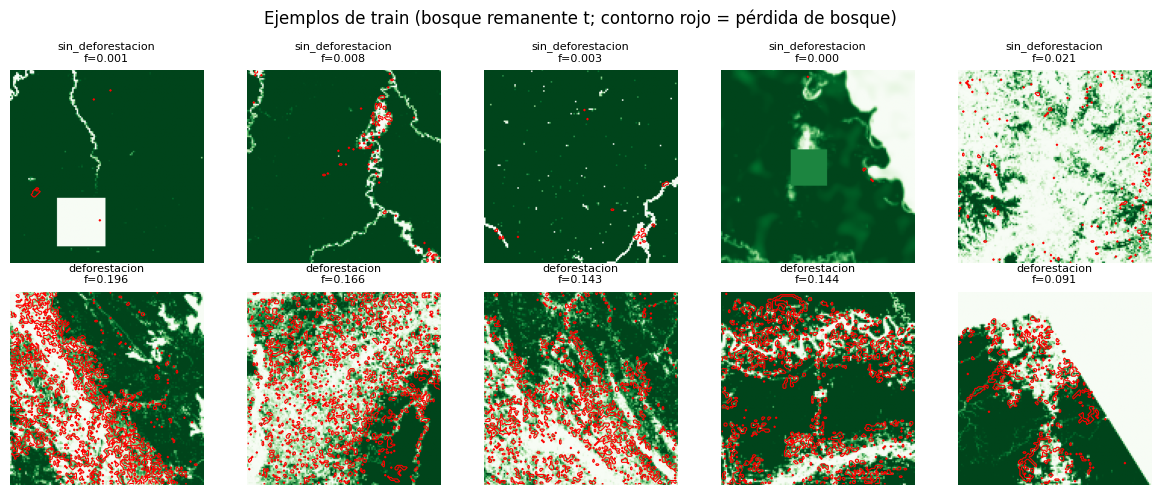

In [6]:
def raw_chw(split, i):
    a = np.asarray(arr(split)[i], dtype=np.float32)
    if LAYOUT == "NHWC": a = a.transpose(2, 0, 1)
    elif LAYOUT == "NHW": a = a[None]
    return a

rng = np.random.RandomState(SEED)
stat_idx = rng.choice(len(train_s), min(500, len(train_s)), replace=False)
stride = max(1, min(H, W) // 64)                                         # submuestreo espacial para ahorrar RAM
stack = np.stack([raw_chw(*train_s[j][:2])[:, ::stride, ::stride] for j in stat_idx])   # (n, C, h, w)
MEAN_ALL = np.nanmean(stack, axis=(0, 2, 3)).astype(np.float32)
STD_ALL  = (np.nanstd(stack, axis=(0, 2, 3)) + 1e-6).astype(np.float32)
RAW_NONNEG = bool(np.nanmin(stack) >= 0)
band_df = pd.DataFrame(dict(banda=BAND_NAMES, media=MEAN_ALL, std=STD_ALL,
                            p02=np.nanpercentile(stack, 2, axis=(0, 2, 3)), p98=np.nanpercentile(stack, 98, axis=(0, 2, 3))))
display(band_df.round(4)); save_table(band_df, "estadisticos_bandas")
del stack

# distribución de clases
parts = {"train": train_s, "val interna": ival_s, HOLDOUT_NAME: holdout}
if extra_test: parts["test"] = extra_test
dist = pd.DataFrame({n: Counter(CLASSES[t[2]] for t in S) for n, S in parts.items()}).reindex(CLASSES).fillna(0).astype(int)
dist.loc["TOTAL"] = dist.sum(); display(dist)
save_table(dist.reset_index().rename(columns={"index": "clase"}), "distribucion_clases")
cnt = Counter(t[2] for t in train_s)
print(f"Razón de desbalance en train: {max(cnt.values()) / max(1, min(cnt.values())):.2f}")
if min(cnt.values()) / len(train_s) < 0.05:
    print("ATENCIÓN: una clase tiene < 5 % de los parches; considera ajustar FRAC_THRESHOLD.")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
dist.drop("TOTAL").plot.bar(ax=ax[0]); ax[0].set_xlabel("Clase"); ax[0].set_ylabel("Número de parches")
ax[0].set_title("Distribución de clases por partición"); ax[0].tick_params(axis="x", rotation=0)
if Y_KIND != "clase":
    ftr = FRAC["train"]
    ax[1].hist(ftr, bins=50, log=True); ax[1].axvline(FRAC_THRESHOLD, c="r", ls="--", label=f"umbral τ={FRAC_THRESHOLD}")
    ax[1].set_xlabel("Fracción de píxeles con pérdida por parche"); ax[1].set_ylabel("Parches (escala log)")
    ax[1].set_title("Distribución de la fracción de pérdida (train)"); ax[1].legend()
    q = np.nanquantile(ftr, [0.5, 0.75, 0.9, 0.95]); print("Cuantiles 50/75/90/95 % de la fracción:", np.round(q, 4),
          f"| parches con alguna pérdida: {(ftr > 0).mean():.1%}")
plt.tight_layout(); savefig("eda_distribucion"); plt.show()

def rgb_image(split, i):
    a = raw_chw(split, i)
    if not RGB_FOUND:
        b = a[DISPLAY_IDX]; lo, hi = np.nanpercentile(b, 2), np.nanpercentile(b, 98)
        g = np.nan_to_num(np.clip((b - lo) / (hi - lo + 1e-8), 0, 1))
        return plt.cm.Greens(g)[..., :3]
    r = a[RGB_IDX]
    lo, hi = np.nanpercentile(r, 2), np.nanpercentile(r, 98)
    return np.nan_to_num(np.clip((r - lo) / (hi - lo + 1e-8), 0, 1)).transpose(1, 2, 0)

def loss_mask(split, i):
    p = npy_path(split, "y")
    if p is None or Y_KIND != "mascara": return None
    return to_hw(arr(split, "y")[i:i + 1])[0] > MASK_POSITIVE_MIN

n_show = 5
fig, axes = plt.subplots(K, n_show, figsize=(2.4 * n_show, 2.5 * K), squeeze=False)
for k in range(K):
    pool = [t for t in train_s if t[2] == k]
    for j, t in enumerate(random.Random(SEED).sample(pool, min(n_show, len(pool)))):
        axes[k, j].imshow(rgb_image(*t[:2]))
        m = loss_mask(*t[:2])
        if m is not None and m.any(): axes[k, j].contour(m, levels=[0.5], colors="red", linewidths=0.8)
        ttl = CLASSES[k] + (f"\nf={FRAC['train'][t[1]]:.3f}" if Y_KIND != "clase" else "")
        axes[k, j].set_title(ttl, fontsize=8)
    for j in range(n_show): axes[k, j].axis("off")
plt.suptitle(f"Ejemplos de train ({'RGB' if RGB_FOUND else BAND_NAMES[DISPLAY_IDX]}; contorno rojo = pérdida de bosque)"); plt.tight_layout(); savefig("eda_ejemplos"); plt.show()

### 3.2 Dataset y aumentos
Los parches no tienen orientación canónica: volteos horizontales/verticales y rotaciones de 90° se aplican **igual a la entrada, a la máscara de pérdida y a la máscara de validez**; un *jitter* suave de ganancia y sesgo se aplica solo a la entrada. Para entrenar, el *DataLoader* entrega también las máscaras (`masks=True`).

In [7]:
assert Y_KIND == "mascara", "TransUNet++ necesita máscaras de pérdida (Y) por píxel."

def get_masks(split, i):
    ym = (to_hw(arr(split, "y")[i:i + 1])[0] > MASK_POSITIVE_MIN).astype(np.float32)
    if npy_path(split, "m") is not None and USE_VALID_MASK:
        vm = (to_hw(arr(split, "m")[i:i + 1])[0] > 0.5).astype(np.float32)
    else:
        vm = np.ones_like(ym)
    return ym * vm, vm

class NpyDS(Dataset):
    def __init__(self, samples, train=False, augment=True, ch_order=None, masks=False):
        self.samples, self.train, self.augment, self.masks = samples, train, augment, masks
        self.ch = list(ch_order if ch_order is not None else CH_ORDER)
        self.mean = torch.tensor(MEAN_ALL[self.ch])[:, None, None]
        self.std  = torch.tensor(STD_ALL[self.ch])[:, None, None]
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, j):
        s, i, y = self.samples[j]
        x = torch.from_numpy(raw_chw(s, i)[self.ch])
        x = torch.nan_to_num((x - self.mean) / self.std, nan=0.0, posinf=0.0, neginf=0.0)
        if self.masks:
            ym, vm = get_masks(s, i)
            z = torch.cat([x, torch.from_numpy(ym)[None], torch.from_numpy(vm)[None]], 0)
        else:
            z = x
        if self.train and self.augment:
            if torch.rand(1) < 0.5: z = z.flip(-1)
            if torch.rand(1) < 0.5: z = z.flip(-2)
            if z.shape[-1] == z.shape[-2]: z = torch.rot90(z, int(torch.randint(0, 4, (1,))), dims=(-2, -1))
        x = z[:len(self.ch)]
        if self.train and self.augment:
            x = x * (1 + 0.1 * (2 * torch.rand(x.shape[0], 1, 1) - 1)) + 0.1 * (2 * torch.rand(x.shape[0], 1, 1) - 1)
        if self.masks:
            return x.contiguous(), y, j, z[-2:-1].contiguous(), z[-1:].contiguous()
        return x.contiguous(), y, j

def seed_worker(_):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def make_loader(samples, train, augment=True, seed=SEED, bs=BATCH_SIZE, ch_order=None, masks=False):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(NpyDS(samples, train, augment, ch_order, masks), batch_size=bs, shuffle=train,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                      worker_init_fn=seed_worker, generator=g, drop_last=train and len(samples) > bs)

def class_weights_tensor(samples):
    cnt = Counter(t[2] for t in samples); n = len(samples)
    return torch.tensor([n / (K * max(1, cnt.get(k, 0))) for k in range(K)], dtype=torch.float32, device=DEVICE)

xb, yb, _, mb, vb = next(iter(make_loader(train_s, True, masks=True)))
print("Lote:", tuple(xb.shape), "| máscara:", tuple(mb.shape), "| media", round(xb.mean().item(), 3), "| d.e.", round(xb.std().item(), 3),
      f"| píxeles con pérdida en el lote: {mb.sum().item() / vb.sum().clamp(min=1).item():.2%}")
print("Pesos de clase:", dict(zip(CLASSES, class_weights_tensor(train_s).cpu().numpy().round(3))))

Lote: (32, 31, 128, 128) | máscara: (32, 1, 128, 128) | media 0.014 | d.e. 0.958 | píxeles con pérdida en el lote: 6.64%
Pesos de clase: {'sin_deforestacion': np.float32(1.084), 'deforestacion': np.float32(0.928)}


## 4. Modelo: TransUNet++ y formulación matemática (R1)
**Encoder CNN.** $D + 1$ niveles (`DEPTH` = $D$) de bloques $[\text{Conv}_{3\times3} \to \text{BN} \to \text{ReLU}]\times 2$ separados por *max-pooling* $2\times2$, con canales $32 \to 64 \to 128 \to 256 \to 512$, producen los nodos $X^{i,0}$, $i = 0, \dots, D$, a partir de las $C_{in}$ capas del parche.

**Transformer en el *bottleneck*** (TransUNet). El mapa $X^{D,0} \in \mathbb{R}^{C_D \times h \times w}$ se aplana en $N = hw$ *tokens* y se proyecta: $\mathbf{z}_0 = X^{D,0}_{\text{flat}} W_E + E_{\text{pos}}$, con $W_E \in \mathbb{R}^{C_D \times d}$ y posiciones aprendidas $E_{\text{pos}} \in \mathbb{R}^{N \times d}$. Cada una de las $L$ capas (*pre-norm*) aplica
$$\mathbf{z}'_\ell = \mathbf{z}_{\ell-1} + \text{MSA}(\text{LN}(\mathbf{z}_{\ell-1})), \qquad \mathbf{z}_\ell = \mathbf{z}'_\ell + \text{MLP}(\text{LN}(\mathbf{z}'_\ell)),$$
$$\text{MSA}(\mathbf{z}) = [\text{head}_1, \dots, \text{head}_H]\,W^O, \qquad \text{head}_k = \text{softmax}\!\Big(\frac{Q_k K_k^\top}{\sqrt{d/H}}\Big) V_k,$$
de modo que cada posición del *bottleneck* atiende a **todo el parche** (contexto global: relación entre vías, frontera agropecuaria y bosque remanente). La salida se reproyecta y se suma de forma residual: $\tilde X^{D,0} = X^{D,0} + \text{reshape}(\text{LN}(\mathbf{z}_L) W_O)$.

**Decoder anidado y denso** (UNet++). Para $j \ge 1$, cada nodo combina todos los nodos previos de su misma escala y el nodo sobremuestreado de la escala inferior:
$$X^{i,j} = \mathcal{H}\Big(\big[X^{i,0}, X^{i,1}, \dots, X^{i,j-1},\ \text{Up}(X^{i+1,j-1})\big]\Big), \qquad i = 0, \dots, D - j,$$
con $\mathcal{H}$ un bloque convolucional y $\text{Up}$ interpolación bilineal $\times 2$ (usando $\tilde X^{D,0}$ en la escala más baja). Esto "acerca" semánticamente los mapas del encoder a los del decoder antes de fusionarlos.

**Supervisión profunda.** Cada nodo $X^{0,j}$, $j = 1, \dots, D$, tiene una cabeza $1\times1$ que da logits $z^{(j)}_{ij}$; la pérdida de segmentación se promedia sobre las $D$ cabezas y la predicción final es $\hat p_{ij} = \sigma\big(\frac1D \sum_j z^{(j)}_{ij}\big)$.

**Cabeza de clasificación auxiliar.** $\text{GAP}(\tilde X^{D,0}) \to \text{Dropout}(p) \to \text{Linear}(\cdot, K)$ predice la clase del parche.

**Pérdida multitarea.** Con máscara de pérdida $Y_{ij}$ y de validez $M_{ij}$:
$$\mathcal{L}_{\text{BCE}} = \frac{\sum_{ij} M_{ij}\,\big[-Y_{ij}\log\hat p_{ij} - (1-Y_{ij})\log(1-\hat p_{ij})\big]}{\sum_{ij} M_{ij}}, \qquad
\mathcal{L}_{\text{Dice}} = 1 - \frac{2\sum_{ij} M_{ij}\hat p_{ij} Y_{ij} + 1}{\sum_{ij} M_{ij}\hat p_{ij} + \sum_{ij} M_{ij} Y_{ij} + 1},$$
$$\mathcal{L} = \mathcal{L}_{\text{CE}}^{\text{parche}} + \lambda\,\frac{1}{D}\sum_{j=1}^{D}\big(\mathcal{L}_{\text{BCE}}^{(j)} + \mathcal{L}_{\text{Dice}}^{(j)}\big), \qquad \lambda = \texttt{SEG\_LOSS\_WEIGHT},$$
donde $\mathcal{L}_{\text{CE}}^{\text{parche}}$ es la entropía cruzada ponderada ($w_k = \frac{N}{K n_k}$) con suavizado de etiquetas $\varepsilon$:
$$\ell_i = (1-\varepsilon)\, w_{y_i}\,[-\log p_{i,y_i}] + \frac{\varepsilon}{K}\sum_{k=1}^{K} w_k\,[-\log p_{i,k}], \qquad \mathcal{L}_{\text{CE}}^{\text{parche}} = \frac{\sum_i \ell_i}{\sum_i w_{y_i}}.$$
El término Dice compensa el fuerte desbalance de píxeles (la pérdida ocupa una fracción pequeña del parche).

**Optimización.** AdamW con *warm-up* lineal de $s_w$ pasos y decaimiento coseno:
$$\eta_t = \eta_0 \cdot \begin{cases} \frac{t+1}{s_w} & t < s_w \\ \max\!\left(0.01,\ \tfrac12\left[1+\cos\!\left(\pi\frac{t-s_w}{S-s_w}\right)\right]\right) & t \ge s_w \end{cases}$$
Precisión mixta (AMP) en GPU, recorte de gradiente (`GRAD_CLIP`) y *early stopping* sobre el **F1-macro por parche de la validación interna**. La red se entrena desde cero.

**Métricas.** Por parche: F1-macro (principal), *balanced accuracy*, AUC-ROC, MCC, κ de Cohen y accuracy. Por píxel (sobre píxeles válidos): IoU, Dice/F1, precisión, recall y AP.

In [8]:
ARCH = "transunetpp"
ARCH_LABEL = "TransUNet++"

class ConvBlock(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class Encoder(nn.Module):
    def __init__(self, cin, chs):
        super().__init__()
        self.blocks = nn.ModuleList([ConvBlock(cin if i == 0 else chs[i - 1], c) for i, c in enumerate(chs)])
        self.pool = nn.MaxPool2d(2)
    def forward(self, x):
        feats = []
        for i, b in enumerate(self.blocks):
            x = b(x if i == 0 else self.pool(x)); feats.append(x)
        return feats

class TransformerBottleneck(nn.Module):
    # tokens espaciales del bottleneck → Transformer pre-norm → reproyección residual
    def __init__(self, ch, n_tokens, dim=EMBED_DIM, layers=TRANS_LAYERS, heads=N_HEADS, dropout=TRANS_DROPOUT):
        super().__init__()
        self.inp = nn.Linear(ch, dim)
        self.pos = nn.Parameter(torch.zeros(1, n_tokens, dim)); nn.init.trunc_normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(dim, heads, dim_feedforward=4 * dim, dropout=dropout, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.tf = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim); self.out = nn.Linear(dim, ch)
    def forward(self, f):
        B, C, h, w = f.shape
        t = self.inp(f.flatten(2).transpose(1, 2))                         # (B, N, d)
        pos = self.pos
        if pos.shape[1] != h * w:                                          # otro tamaño de parche: interpolar posiciones
            s0 = int(round(pos.shape[1] ** 0.5))
            pos = F.interpolate(pos.transpose(1, 2).reshape(1, -1, s0, s0), size=(h, w), mode="bilinear",
                                align_corners=False).flatten(2).transpose(1, 2)
        t = self.tf(t + pos)
        return f + self.out(self.norm(t)).transpose(1, 2).reshape(B, C, h, w)

class TransUNetPP(nn.Module):
    def __init__(self, num_classes, c_in=None, base=BASE_CH, depth=DEPTH, trans_layers=TRANS_LAYERS,
                 nested=NESTED_SKIPS, deep_sup=DEEP_SUPERVISION, dropout=DROPOUT, img_hw=None):
        super().__init__()
        self.D, self.mult, self.nested = depth, 2 ** depth, nested
        self.deep_sup = deep_sup and nested
        chs = [base * 2**i for i in range(depth + 1)]
        self.enc = Encoder(c_in or C_IN, chs)
        hh, ww = img_hw or (H, W)
        n_tok = (math.ceil(hh / self.mult)) * (math.ceil(ww / self.mult))
        self.trans = TransformerBottleneck(chs[-1], n_tok, layers=trans_layers) if trans_layers > 0 else nn.Identity()
        self.bott = nn.Identity()                      # punto de anclaje para Grad-CAM (bottleneck tras el Transformer)
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        if nested:                                     # nodos X^{i,j} de UNet++
            self.nodes = nn.ModuleDict({f"{i}_{j}": ConvBlock(j * chs[i] + chs[i + 1], chs[i])
                                        for j in range(1, depth + 1) for i in range(0, depth + 1 - j)})
            n_heads = depth if self.deep_sup else 1
        else:                                          # decoder con skips simples
            self.decs = nn.ModuleList([ConvBlock(chs[i] + chs[i + 1], chs[i]) for i in reversed(range(depth))])
            n_heads = 1
        self.seg_heads = nn.ModuleList([nn.Conv2d(chs[0], 1, 1) for _ in range(n_heads)])
        self.cls_head = nn.Sequential(nn.Dropout(dropout), nn.Linear(chs[-1], num_classes))
        self.used_pretrained = False

    def encode(self, x):
        Hh, Ww = x.shape[-2:]; ph, pw = (-Hh) % self.mult, (-Ww) % self.mult
        if ph or pw: x = F.pad(x, (0, pw, 0, ph), mode="replicate")
        g = self.enc(x); g[-1] = self.bott(self.trans(g[-1]))
        return g, (Hh, Ww)

    def forward_all(self, x, return_all=False):
        g, (Hh, Ww) = self.encode(x)
        cls = self.cls_head(g[-1].mean((2, 3)))
        if self.nested:
            X = {(i, 0): g[i] for i in range(self.D + 1)}
            for j in range(1, self.D + 1):
                for i in range(0, self.D + 1 - j):
                    X[(i, j)] = self.nodes[f"{i}_{j}"](torch.cat([X[(i, k)] for k in range(j)] + [self.up(X[(i + 1, j - 1)])], 1))
            tops = [X[(0, j)] for j in range(1, self.D + 1)] if self.deep_sup else [X[(0, self.D)]]
        else:
            d = g[-1]
            for dec, skip in zip(self.decs, reversed(g[:-1])):
                d = dec(torch.cat([skip, self.up(d)], 1))
            tops = [d]
        segs = [h(t)[..., :Hh, :Ww] for h, t in zip(self.seg_heads, tops)]
        if return_all:
            return cls, segs
        return cls, torch.stack(segs, 0).mean(0)

    def forward(self, x):                 # logits por parche (interfaz común con el resto de la plantilla)
        return self.forward_all(x)[0]
    def segment(self, x):                 # logits por píxel (promedio de las cabezas)
        return self.forward_all(x)[1]
    def embed(self, x):                   # embedding del bottleneck
        return self.encode(x)[0][-1].mean((2, 3))

def build_model(num_classes, base=BASE_CH, depth=DEPTH, trans_layers=TRANS_LAYERS, nested=NESTED_SKIPS,
                deep_sup=DEEP_SUPERVISION, dropout=DROPOUT):
    return TransUNetPP(num_classes, base=base, depth=depth, trans_layers=trans_layers, nested=nested,
                       deep_sup=deep_sup, dropout=dropout)

class Embedder(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, x): return self.m.embed(x)

def make_scheduler(opt, total_steps, warmup_steps):
    def f(step):
        if step < warmup_steps: return (step + 1) / max(1, warmup_steps)
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return max(0.01, 0.5 * (1 + math.cos(math.pi * min(1.0, prog))))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def make_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception: return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def seg_loss(logit, ym, vm, use_dice=USE_DICE):
    logit = logit.float()
    bce = F.binary_cross_entropy_with_logits(logit, ym, reduction="none")
    bce = (bce * vm).sum() / vm.sum().clamp(min=1)
    if not use_dice:
        return bce
    p = torch.sigmoid(logit) * vm
    inter = (p * ym).sum((1, 2, 3)); den = p.sum((1, 2, 3)) + (ym * vm).sum((1, 2, 3))
    return bce + (1 - (2 * inter + 1) / (den + 1)).mean()

def compute_metrics(y, prob):
    pred = prob.argmax(1); L = list(range(K))
    m = dict(accuracy=accuracy_score(y, pred), balanced_acc=balanced_accuracy_score(y, pred),
             f1_macro=f1_score(y, pred, average="macro", labels=L, zero_division=0),
             precision_macro=precision_score(y, pred, average="macro", labels=L, zero_division=0),
             recall_macro=recall_score(y, pred, average="macro", labels=L, zero_division=0),
             f1_weighted=f1_score(y, pred, average="weighted", labels=L, zero_division=0),
             mcc=matthews_corrcoef(y, pred), kappa=cohen_kappa_score(y, pred))
    try:
        m["auc"] = roc_auc_score(y, prob[:, 1]) if K == 2 else roc_auc_score(y, prob, multi_class="ovr", average="macro", labels=L)
    except ValueError:
        m["auc"] = float("nan")
    return m

@torch.no_grad()
def predict(model, loader):
    model.eval(); ys, ps, idx = [], [], []
    for batch in loader:
        x, y, i = batch[:3]
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(x.to(DEVICE, non_blocking=True))
        ps.append(logits.float().softmax(1).cpu()); ys.append(y); idx.append(i)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(idx).numpy()

@torch.no_grad()
def predict_full(model, loader, ap_pixels=2000, seed=SEED):
    # por parche (y, p, idx) + segmentación: conteos TP/FP/FN, fracción predicha y muestra de píxeles para AP
    model.eval(); ys, ps, idx, fr = [], [], [], []
    tp = fp = fn = 0.0; g = torch.Generator().manual_seed(seed); pix_p, pix_y = [], []
    for x, y, i, ym, vm in loader:
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            cls, seg = model.forward_all(x.to(DEVICE, non_blocking=True))
        pr = torch.sigmoid(seg.float()).cpu(); hard = (pr > 0.5).float()
        tp += (hard * ym * vm).sum().item(); fp += (hard * (1 - ym) * vm).sum().item(); fn += ((1 - hard) * ym * vm).sum().item()
        fr.append(((hard * vm).sum((1, 2, 3)) / vm.sum((1, 2, 3)).clamp(min=1)))
        sel = vm.flatten() > 0
        pv, yv = pr.flatten()[sel], ym.flatten()[sel]
        if len(pv):
            k = torch.randperm(len(pv), generator=g)[:ap_pixels]; pix_p.append(pv[k]); pix_y.append(yv[k])
        ps.append(cls.float().softmax(1).cpu()); ys.append(y); idx.append(i)
    pix_p, pix_y = torch.cat(pix_p).numpy(), torch.cat(pix_y).numpy()
    seg_m = dict(iou_pix=tp / max(1, tp + fp + fn), dice_pix=2 * tp / max(1, 2 * tp + fp + fn),
                 precision_pix=tp / max(1, tp + fp), recall_pix=tp / max(1, tp + fn),
                 ap_pix=average_precision_score(pix_y, pix_p) if pix_y.min() != pix_y.max() else float("nan"))
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(idx).numpy(), seg_m, torch.cat(fr).numpy()

def train_model(train_samples, val_samples, *, epochs=EPOCHS, seed=SEED, base=BASE_CH, depth=DEPTH,
                trans_layers=TRANS_LAYERS, nested=NESTED_SKIPS, deep_sup=DEEP_SUPERVISION,
                use_dice=USE_DICE, seg_weight=SEG_LOSS_WEIGHT, augment=AUGMENT, use_class_weights=USE_CLASS_WEIGHTS,
                label_smoothing=LABEL_SMOOTHING, lr=LR, patience=PATIENCE, tag="principal", group="principal", verbose=True):
    set_seed(seed)
    tl = make_loader(train_samples, True, augment, seed, masks=True)
    vl = make_loader(val_samples, False, seed=seed, masks=True)
    model = build_model(K, base=base, depth=depth, trans_layers=trans_layers, nested=nested, deep_sup=deep_sup).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=class_weights_tensor(train_samples) if use_class_weights else None,
                               label_smoothing=label_smoothing)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    sch = make_scheduler(opt, epochs * len(tl), WARMUP_EPOCHS * len(tl) if epochs > 1 else 0)
    scaler = make_scaler()
    best, best_state, best_ep, bad, hist = -1.0, None, 0, 0, []
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        tot, tot_seg, correct, n = 0.0, 0.0, 0, 0
        for x, y, _, ym, vm in tl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            ym, vm = ym.to(DEVICE, non_blocking=True), vm.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                cls, segs = model.forward_all(x, return_all=True)
                l_cls = crit(cls, y)
            l_seg = (torch.stack([seg_loss(sg, ym, vm, use_dice) for sg in segs]).mean() if seg_weight > 0
                     else torch.zeros((), device=DEVICE))
            loss = l_cls + seg_weight * l_seg
            scaler.scale(loss).backward()
            if GRAD_CLIP:
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(opt); scaler.update(); sch.step()
            tot += loss.item() * x.size(0); tot_seg += l_seg.item() * x.size(0)
            correct += (cls.argmax(1) == y).sum().item(); n += x.size(0)
        yv, pv, _, sm, _ = predict_full(model, vl); vm_ = compute_metrics(yv, pv)
        vloss = F.nll_loss(torch.log(torch.tensor(pv) + 1e-12), torch.tensor(yv)).item()
        hist.append(dict(epoch=ep, train_loss=tot / n, train_seg_loss=tot_seg / n, train_acc=correct / n, val_loss=vloss,
                         val_acc=vm_["accuracy"], val_f1_macro=vm_["f1_macro"], val_auc=vm_["auc"],
                         val_iou_pix=sm["iou_pix"], val_dice_pix=sm["dice_pix"], lr=opt.param_groups[0]["lr"],
                         tiempo_s=time.time() - t0))
        improved = vm_["f1_macro"] > best + 1e-4
        if improved:
            best, best_ep, bad = vm_["f1_macro"], ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose:
            print(f"[{tag}] época {ep:02d}/{epochs} | loss {tot/n:.4f} (seg {tot_seg/n:.4f}) | acc {correct/n:.4f} | "
                  f"val_F1 {vm_['f1_macro']:.4f} | val_IoU_pix {sm['iou_pix']:.4f}{'  *' if improved else ''} | {time.time()-t0:.0f}s")
        if bad >= patience:
            if verbose: print(f"Early stopping en la época {ep} (mejor: {best_ep})")
            break
    elapsed = time.time() - t0
    model.load_state_dict(best_state)
    log_compute(tag, group, elapsed)
    return model, pd.DataFrame(hist), dict(best_epoch=best_ep, best_val_f1=best, seconds=elapsed, used_pretrained=False)

_tmp = build_model(K)
print(f"Arquitectura: {ARCH_LABEL} (DEPTH={DEPTH}, BASE_CH={BASE_CH}, Transformer={TRANS_LAYERS}×{EMBED_DIM}d/{N_HEADS}h, "
      f"anidado={NESTED_SKIPS}, deep_sup={DEEP_SUPERVISION}) | parámetros: {sum(p.numel() for p in _tmp.parameters()) / 1e6:.2f} M | entrada {C_IN} canales")
with torch.no_grad():
    c_, s_ = _tmp.forward_all(torch.zeros(2, C_IN, H, W))
print("Salidas:", tuple(c_.shape), "(parche) |", tuple(s_.shape), "(píxel)"); del _tmp

Arquitectura: TransUNet++ (DEPTH=4, BASE_CH=32, Transformer=4×256d/8h, anidado=True, deep_sup=True) | parámetros: 12.61 M | entrada 31 canales
Salidas: (2, 2) (parche) | (2, 1, 128, 128) (píxel)


## 5. Entrenamiento del modelo principal

In [9]:
model, hist, info = train_model(train_s, ival_s, epochs=EPOCHS, tag=f"{ARCH_LABEL} principal")
hist.to_csv(OUT / "logs" / f"historial_{ARCH}.csv", index=False)
print(info)
CKPT_PATH = CKPT_DIR / f"best_{ARCH}.pt"
torch.save({"state_dict": model.state_dict(), "arch": ARCH, "base_ch": BASE_CH, "depth": DEPTH, "trans_layers": TRANS_LAYERS,
            "nested": NESTED_SKIPS, "deep_sup": DEEP_SUPERVISION, "hw": [int(H), int(W)],
            "classes": CLASSES, "ch_order": CH_ORDER, "band_names": BAND_NAMES,
            "mean_all": MEAN_ALL, "std_all": STD_ALL, "layout": LAYOUT, "dropout": DROPOUT,
            "frac_threshold": FRAC_THRESHOLD, "config": CONFIG, "info": info}, CKPT_PATH)
print("Pesos guardados en", CKPT_PATH, f"({CKPT_PATH.stat().st_size / 1e6:.1f} MB)")

[TransUNet++ principal] época 01/10 | loss 1.6946 (seg 1.2887) | acc 0.8767 | val_F1 0.8262 | val_IoU_pix 0.0382  * | 92s
[TransUNet++ principal] época 02/10 | loss 1.4179 (seg 1.0550) | acc 0.9056 | val_F1 0.7875 | val_IoU_pix 0.1331 | 184s
[TransUNet++ principal] época 03/10 | loss 1.3597 (seg 1.0163) | acc 0.9102 | val_F1 0.8148 | val_IoU_pix 0.1665 | 277s
[TransUNet++ principal] época 04/10 | loss 1.3319 (seg 1.0006) | acc 0.9172 | val_F1 0.8344 | val_IoU_pix 0.1373  * | 369s
[TransUNet++ principal] época 05/10 | loss 1.3179 (seg 0.9936) | acc 0.9226 | val_F1 0.8240 | val_IoU_pix 0.1548 | 461s
[TransUNet++ principal] época 06/10 | loss 1.3057 (seg 0.9889) | acc 0.9258 | val_F1 0.8307 | val_IoU_pix 0.1438 | 553s
[TransUNet++ principal] época 07/10 | loss 1.2949 (seg 0.9854) | acc 0.9294 | val_F1 0.8358 | val_IoU_pix 0.1632  * | 645s
[TransUNet++ principal] época 08/10 | loss 1.2839 (seg 0.9817) | acc 0.9362 | val_F1 0.8371 | val_IoU_pix 0.1684  * | 737s
[TransUNet++ principal] época

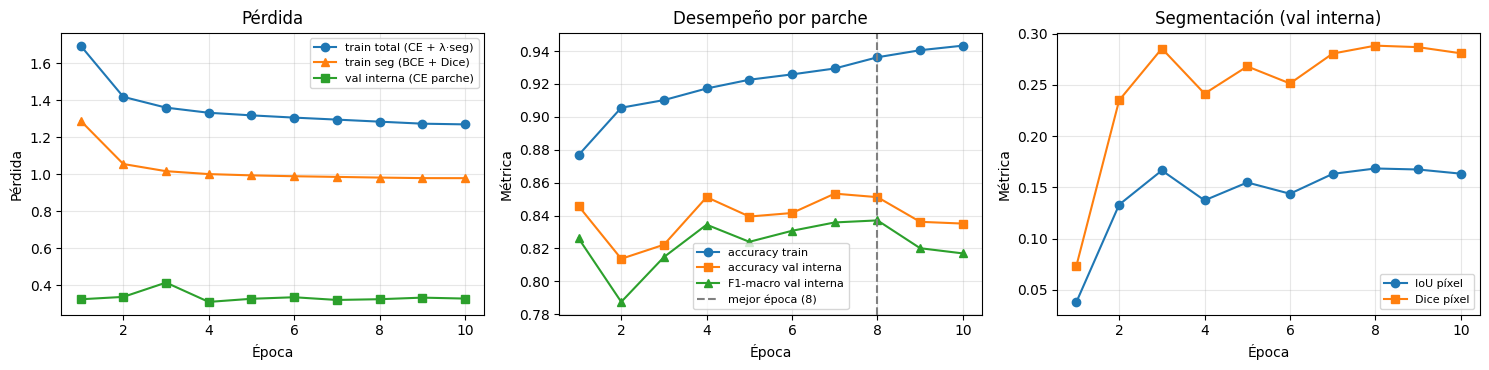

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(hist.epoch, hist.train_loss, "o-", label="train total (CE + λ·seg)")
ax[0].plot(hist.epoch, hist.train_seg_loss, "^-", label="train seg (BCE + Dice)")
ax[0].plot(hist.epoch, hist.val_loss, "s-", label="val interna (CE parche)")
ax[0].set_title("Pérdida"); ax[0].set_ylabel("Pérdida")
ax[1].plot(hist.epoch, hist.train_acc, "o-", label="accuracy train")
ax[1].plot(hist.epoch, hist.val_acc, "s-", label="accuracy val interna")
ax[1].plot(hist.epoch, hist.val_f1_macro, "^-", label="F1-macro val interna")
ax[1].axvline(info["best_epoch"], ls="--", c="gray", label=f"mejor época ({info['best_epoch']})")
ax[1].set_title("Desempeño por parche"); ax[1].set_ylabel("Métrica")
ax[2].plot(hist.epoch, hist.val_iou_pix, "o-", label="IoU píxel"); ax[2].plot(hist.epoch, hist.val_dice_pix, "s-", label="Dice píxel")
ax[2].set_title("Segmentación (val interna)"); ax[2].set_ylabel("Métrica")
for a in ax: a.set_xlabel("Época"); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); savefig("curvas_entrenamiento"); plt.show()

## 6. Evaluación sobre `val` (y `test`)

,conjunto,accuracy,balanced_acc,f1_macro,precision_macro,recall_macro,f1_weighted,mcc,kappa,auc,iou_pix,dice_pix,precision_pix,recall_pix,ap_pix
0,val,0.9030,0.8868,0.8632,0.8454,0.8868,0.9057,0.7310,0.727,0.9626,0.1450,0.2533,0.2341,0.2760,0.1992
0,test,0.8759,0.8514,0.8079,0.7812,0.8514,0.8827,0.6288,0.618,0.9449,0.1332,0.2351,0.1952,0.2956,0.1759


Segmentación en val: IoU=0.1450 | Dice=0.2533 | AP=0.1992 | MAE fracción de pérdida=0.0230 | r Pearson=0.591


,precision,recall,f1-score,support
sin_deforestacion,0.9601,0.9149,0.9370,1105.000
deforestacion,0.7307,0.8586,0.7895,297.000
accuracy,0.9030,0.9030,0.9030,0.903
macro avg,0.8454,0.8868,0.8632,1402.000
weighted avg,0.9115,0.9030,0.9057,1402.000


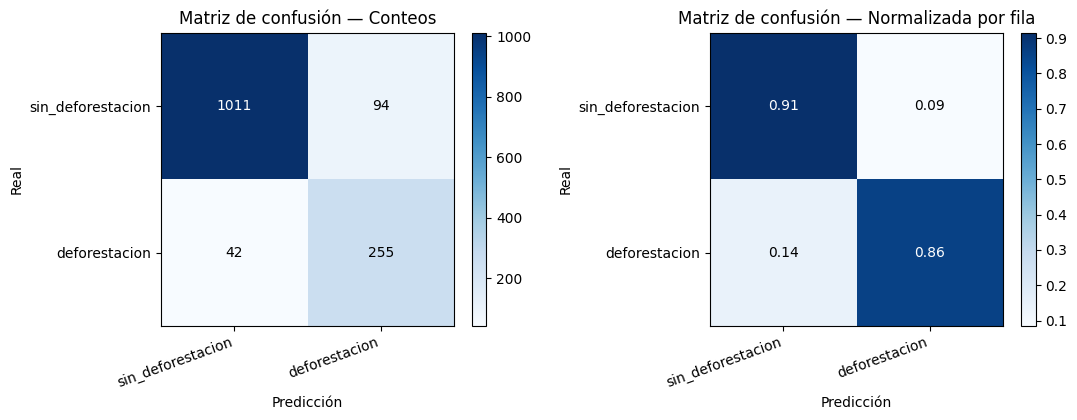

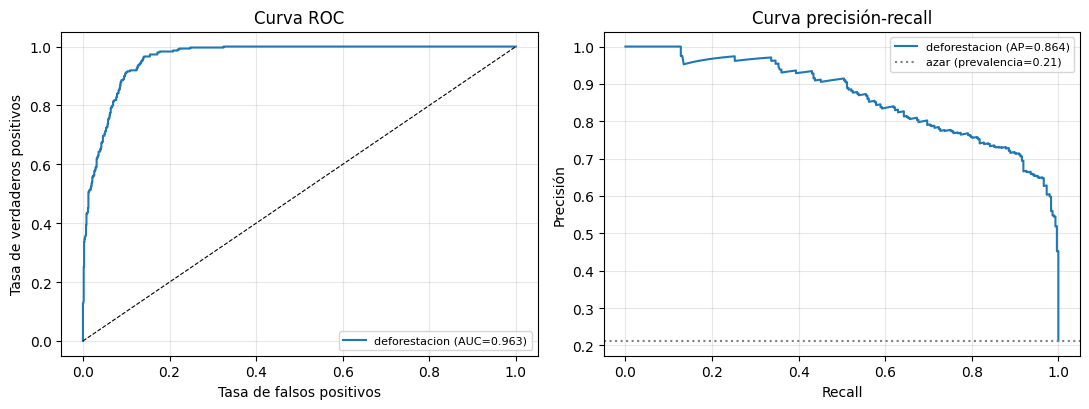

In [11]:
hold_loader = make_loader(holdout, False, masks=True)
y_hold, p_hold, idx_hold, seg_hold, frac_pred_hold = predict_full(model, hold_loader)
pred_hold = p_hold.argmax(1)
m_hold = compute_metrics(y_hold, p_hold)
res_main = pd.DataFrame([{"conjunto": HOLDOUT_NAME, **m_hold, **seg_hold}])
if extra_test:
    y_ext, p_ext, _, seg_ext, _ = predict_full(model, make_loader(extra_test, False, masks=True))
    res_main = pd.concat([res_main, pd.DataFrame([{"conjunto": "test", **compute_metrics(y_ext, p_ext), **seg_ext}])])
display(res_main.round(4)); save_table(res_main, f"metricas_{ARCH}")
true_frac = np.array([FRAC[HOLDOUT_NAME][holdout[j][1]] for j in idx_hold])
print(f"Segmentación en {HOLDOUT_NAME}: IoU={seg_hold['iou_pix']:.4f} | Dice={seg_hold['dice_pix']:.4f} | "
      f"AP={seg_hold['ap_pix']:.4f} | MAE fracción de pérdida={np.abs(frac_pred_hold - true_frac).mean():.4f} | "
      f"r Pearson={np.corrcoef(frac_pred_hold, true_frac)[0, 1]:.3f}")

rep = pd.DataFrame(classification_report(y_hold, pred_hold, labels=list(range(K)), target_names=CLASSES,
                                         output_dict=True, zero_division=0)).T
display(rep.round(4)); save_table(rep.reset_index().rename(columns={"index": "clase"}), "reporte_por_clase")

cm = confusion_matrix(y_hold, pred_hold, labels=list(range(K)))
cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for a, mat, title, fmt in [(ax[0], cm, "Conteos", "d"), (ax[1], cmn, "Normalizada por fila", ".2f")]:
    im = a.imshow(mat, cmap="Blues"); plt.colorbar(im, ax=a, fraction=0.046)
    a.set_xticks(range(K)); a.set_yticks(range(K)); a.set_xticklabels(CLASSES, rotation=20, ha="right"); a.set_yticklabels(CLASSES)
    a.set_xlabel("Predicción"); a.set_ylabel("Real"); a.set_title(f"Matriz de confusión — {title}")
    for i in range(K):
        for j in range(K):
            a.text(j, i, format(mat[i, j], fmt), ha="center", va="center", color="white" if mat[i, j] > mat.max() / 2 else "black")
plt.tight_layout(); savefig("matriz_confusion"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for k in ([1] if K == 2 else range(K)):
    yk = (y_hold == k).astype(int)
    if yk.min() == yk.max(): continue
    fpr, tpr, _ = roc_curve(yk, p_hold[:, k]); pr, rc, _ = precision_recall_curve(yk, p_hold[:, k])
    ax[0].plot(fpr, tpr, label=f"{CLASSES[k]} (AUC={roc_auc_score(yk, p_hold[:, k]):.3f})")
    ax[1].plot(rc, pr, label=f"{CLASSES[k]} (AP={average_precision_score(yk, p_hold[:, k]):.3f})")
    ax[1].axhline(yk.mean(), ls=":", c="gray", label=f"azar (prevalencia={yk.mean():.2f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8)
ax[0].set_xlabel("Tasa de falsos positivos"); ax[0].set_ylabel("Tasa de verdaderos positivos"); ax[0].set_title("Curva ROC")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precisión"); ax[1].set_title("Curva precisión-recall")
for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); savefig("curvas_roc_pr"); plt.show()

## 7. Predicciones sobre `val`
CSV con el índice de cada parche en `val_X.npy`, la clase real y predicha, la confianza, la fracción de pérdida real y **predicha por TransUNet++**, y la probabilidad por clase. Se muestran los mapas de probabilidad de pérdida. Al final, `predecir_parche()` hace inferencia sobre cualquier arreglo nuevo.

1402 predicciones guardadas | aciertos: 0.9030


,particion,indice,clase_real,clase_predicha,confianza,correcto,frac_perdida,frac_valida,frac_predicha,p_sin_deforestacion,p_deforestacion
0,val,0,sin_deforestacion,sin_deforestacion,0.957952,True,0.000196,0.623596,0.000000,0.957952,0.042048
1,val,1,sin_deforestacion,sin_deforestacion,0.968111,True,0.000506,0.964355,0.000506,0.968111,0.031889
2,val,2,sin_deforestacion,sin_deforestacion,0.828592,True,0.039853,0.581970,0.072575,0.828592,0.171408
3,val,3,sin_deforestacion,sin_deforestacion,0.967039,True,0.000563,0.975525,0.000250,0.967039,0.032961
4,val,4,sin_deforestacion,sin_deforestacion,0.967533,True,0.000549,1.000000,0.000000,0.967533,0.032467
5,val,5,sin_deforestacion,sin_deforestacion,0.950180,True,0.006852,0.668030,0.016811,0.950180,0.049820
6,val,6,sin_deforestacion,sin_deforestacion,0.874453,True,0.003102,0.255798,0.000000,0.874453,0.125547
7,val,7,sin_deforestacion,sin_deforestacion,0.965446,True,0.005004,0.927002,0.005136,0.965446,0.034554
8,val,8,sin_deforestacion,sin_deforestacion,0.969062,True,0.000061,1.000000,0.000000,0.969062,0.030938
9,val,9,sin_deforestacion,sin_deforestacion,0.960025,True,0.005428,0.978210,0.018157,0.960025,0.039975


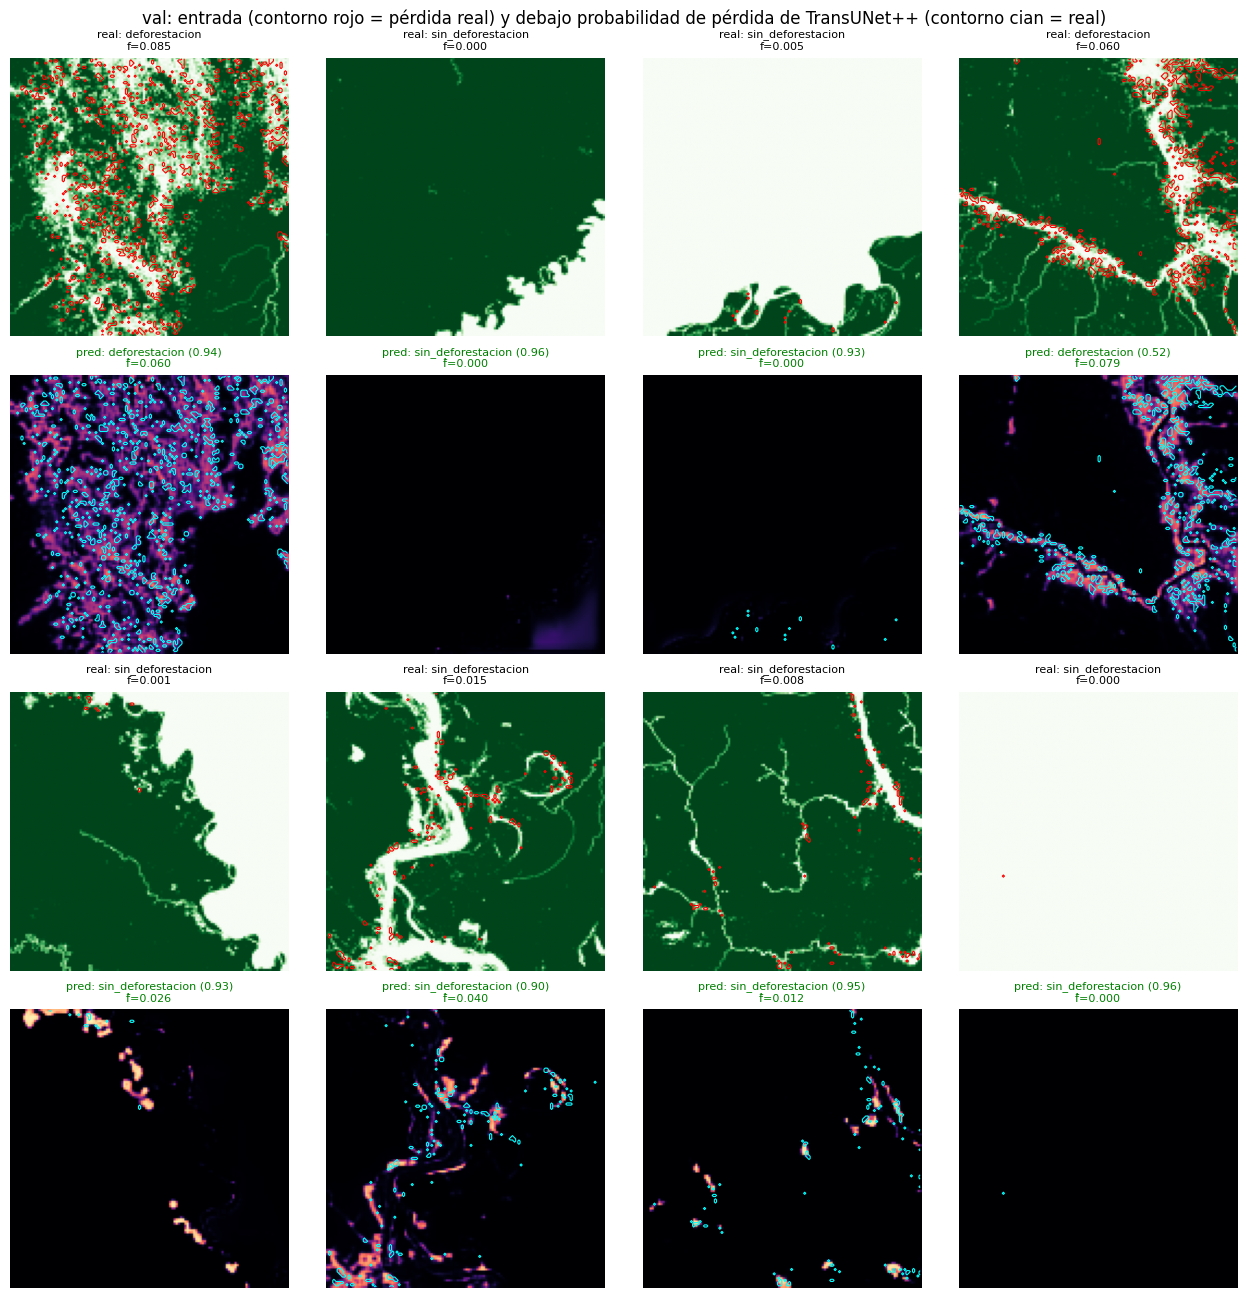

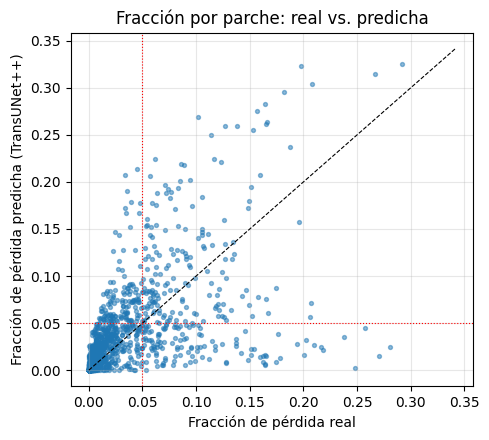

Inferencia con pesos recargados: {'sin_deforestacion': 0.9580000042915344, 'deforestacion': 0.041999999433755875, 'frac_perdida_predicha': 0.0} | real: sin_deforestacion


In [12]:
pred_df = pd.DataFrame({
    "particion": HOLDOUT_NAME, "indice": [holdout[j][1] for j in idx_hold],
    "clase_real": [CLASSES[k] for k in y_hold], "clase_predicha": [CLASSES[k] for k in pred_hold],
    "confianza": p_hold.max(1), "correcto": y_hold == pred_hold,
    "frac_perdida": [FRAC[HOLDOUT_NAME][holdout[j][1]] for j in idx_hold],
    "frac_valida": [VALID[HOLDOUT_NAME][holdout[j][1]] for j in idx_hold],
    "frac_predicha": frac_pred_hold})
for k, c in enumerate(CLASSES):
    pred_df[f"p_{c}"] = p_hold[:, k]
pred_df.to_csv(OUT / "tables" / f"predicciones_{HOLDOUT_NAME}.csv", index=False)
print(f"{len(pred_df)} predicciones guardadas | aciertos: {pred_df.correcto.mean():.4f}")
display(pred_df.head(10))

hold_ds = NpyDS(holdout, False)
pos_of = {holdout[j][1]: j for j in range(len(holdout))}
@torch.no_grad()
def seg_map(indice):
    x = hold_ds[pos_of[indice]][0][None].to(DEVICE)
    return torch.sigmoid(model.eval().segment(x).float())[0, 0].cpu().numpy()

N_SHOW, COLS = 8, 4                                    # número de ejemplos y columnas máximas
sel = pred_df.sample(min(N_SHOW, len(pred_df)), random_state=SEED)
n_rows = math.ceil(len(sel) / COLS)                    # filas de ejemplos (cada una ocupa 2 filas de imágenes)
fig, axes = plt.subplots(2 * n_rows, COLS, figsize=(3.2 * COLS, 3.3 * 2 * n_rows), squeeze=False)
for j, (_, r) in enumerate(sel.iterrows()):
    rr, cc = 2 * (j // COLS), j % COLS
    m = loss_mask(HOLDOUT_NAME, r.indice); pm = seg_map(r.indice)
    axes[rr, cc].imshow(rgb_image(HOLDOUT_NAME, r.indice))
    if m is not None and m.any(): axes[rr, cc].contour(m, levels=[0.5], colors="red", linewidths=0.8)
    axes[rr, cc].set_title(f"real: {r.clase_real}\nf={r.frac_perdida:.3f}", fontsize=8)
    axes[rr + 1, cc].imshow(pm, cmap="magma", vmin=0, vmax=1)
    if m is not None and m.any(): axes[rr + 1, cc].contour(m, levels=[0.5], colors="cyan", linewidths=0.8)
    axes[rr + 1, cc].set_title(f"pred: {r.clase_predicha} ({r.confianza:.2f})\nf̂={r.frac_predicha:.3f}", fontsize=8,
                               color="green" if r.correcto else "red")
for a in axes.flat: a.axis("off")
plt.suptitle(f"{HOLDOUT_NAME}: entrada (contorno rojo = pérdida real) y debajo probabilidad de pérdida de TransUNet++ (contorno cian = real)")
plt.tight_layout(); savefig("predicciones_ejemplos"); plt.show()

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(pred_df.frac_perdida, pred_df.frac_predicha, s=8, alpha=.5)
lim = max(pred_df.frac_perdida.max(), pred_df.frac_predicha.max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=.8); ax.axvline(FRAC_THRESHOLD, c="r", ls=":", lw=.8); ax.axhline(FRAC_THRESHOLD, c="r", ls=":", lw=.8)
ax.set_xlabel("Fracción de pérdida real"); ax.set_ylabel("Fracción de pérdida predicha (TransUNet++)")
ax.set_title("Fracción por parche: real vs. predicha"); ax.grid(alpha=.3)
plt.tight_layout(); savefig("fraccion_real_vs_predicha"); plt.show()

def load_model(path=CKPT_PATH):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = TransUNetPP(len(ck["classes"]), c_in=len(ck["ch_order"]), base=ck["base_ch"], depth=ck["depth"],
                    trans_layers=ck["trans_layers"], nested=ck["nested"], deep_sup=ck["deep_sup"],
                    dropout=ck["dropout"], img_hw=tuple(ck["hw"]))
    m.load_state_dict(ck["state_dict"]); return m.to(DEVICE).eval(), ck

@torch.no_grad()
def predecir_parche(x_raw, m=None, ck=None):
    # x_raw: un parche con la misma disposición que X (p. ej. H×W×C sin normalizar)
    m = m or model
    ch = ck["ch_order"] if ck else CH_ORDER
    mean, std = (ck["mean_all"], ck["std_all"]) if ck else (MEAN_ALL, STD_ALL)
    lay = ck["layout"] if ck else LAYOUT
    a = np.asarray(x_raw, dtype=np.float32)
    a = a.transpose(2, 0, 1) if lay == "NHWC" else (a[None] if lay == "NHW" else a)
    x = np.nan_to_num((a[ch] - mean[ch, None, None]) / std[ch, None, None])
    cls, seg = m.eval().forward_all(torch.from_numpy(x)[None].to(DEVICE))
    p = cls.softmax(1)[0].cpu().numpy()
    out = dict(zip(ck["classes"] if ck else CLASSES, p.round(4).tolist()))
    out["frac_perdida_predicha"] = round(float((torch.sigmoid(seg) > 0.5).float().mean()), 4)
    return out

m_loaded, ck_loaded = load_model()
i0 = holdout[0][1]
print("Inferencia con pesos recargados:", predecir_parche(arr(HOLDOUT_NAME)[i0], m_loaded, ck_loaded),
      "| real:", CLASSES[holdout[0][2]])
del m_loaded

## 8. Líneas base (R3)
1. **Random Forest con estadísticos por banda**: media, desviación y percentiles 10/50/90 de cada banda estandarizada, magnitud de gradiente (textura) e índice de verdor ExG; e **NDVI** si hay banda NIR y los valores crudos son no negativos. `max_depth` elegido en la validación interna.
2. **Regresión logística** sobre los mismos descriptores manuales (modelo lineal clásico). `C` elegido en la validación interna.

Descriptores manuales por parche: 161
RF max_depth=None: F1 val interna=0.7986
RF max_depth=10: F1 val interna=0.8032
RF max_depth=20: F1 val interna=0.7937
LogReg C=0.01: F1 val interna=0.7529
LogReg C=0.1: F1 val interna=0.7779
LogReg C=1.0: F1 val interna=0.8072
LogReg C=10.0: F1 val interna=0.8076


,modelo,accuracy,balanced_acc,f1_macro,precision_macro,recall_macro,f1_weighted,mcc,kappa,auc
0,Random Forest (estadísticos por banda),0.9066,0.8976,0.8695,0.8492,0.8976,0.9096,0.7452,0.7397,0.9660
1,Reg. logística (estadísticos por banda),0.8894,0.8745,0.8463,0.8264,0.8745,0.8932,0.6993,0.6935,0.9593
2,TransUNet++ (propuesto),0.9030,0.8868,0.8632,0.8454,0.8868,0.9057,0.7310,0.7270,0.9626


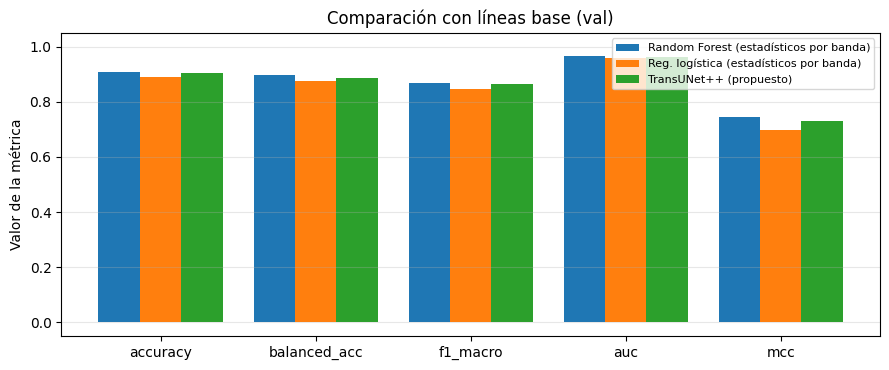

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

QS = torch.tensor([0.1, 0.5, 0.9])
r_pos = CH_ORDER.index(RGB_IDX[0]) if RGB_IDX[0] in CH_ORDER else None
n_pos = CH_ORDER.index(NIR_IDX) if (NIR_IDX is not None and NIR_IDX in CH_ORDER) else None

def handcrafted_batch(x):
    xs = F.adaptive_avg_pool2d(x, (min(x.shape[-2], 64), min(x.shape[-1], 64)))
    flat = xs.flatten(2)
    f = [flat.mean(2), flat.std(2), torch.quantile(flat, QS, dim=2).permute(1, 2, 0).flatten(1)]
    g = xs.mean(1); gx, gy = g[:, :, 1:] - g[:, :, :-1], g[:, 1:, :] - g[:, :-1, :]
    f += [torch.stack([gx.abs().mean((1, 2)), gy.abs().mean((1, 2)), gx.std((1, 2)), gy.std((1, 2))], 1)]
    if xs.shape[1] >= 3:
        exg = 2 * xs[:, 1] - xs[:, 0] - xs[:, 2]; f += [torch.stack([exg.mean((1, 2)), exg.std((1, 2))], 1)]
    if RAW_NONNEG and r_pos is not None and n_pos is not None:
        mean_t, std_t = torch.tensor(MEAN_ALL[CH_ORDER]), torch.tensor(STD_ALL[CH_ORDER])
        nir = xs[:, n_pos] * std_t[n_pos] + mean_t[n_pos]; red = xs[:, r_pos] * std_t[r_pos] + mean_t[r_pos]
        ndvi = (nir - red) / (nir + red + 1e-6); f += [torch.stack([ndvi.mean((1, 2)), ndvi.std((1, 2))], 1)]
    return torch.cat(f, 1)

def handcrafted_features(samples):
    fs, ys = [], []
    for x, y, _ in make_loader(samples, False, masks=False):
        fs.append(handcrafted_batch(x)); ys.append(y)
    return torch.cat(fs).numpy(), torch.cat(ys).numpy()

@torch.no_grad()
def extract_features(net, samples, ch_order=None):
    net.eval(); fs, ys = [], []
    for x, y, _ in make_loader(samples, False, ch_order=ch_order, masks=False):
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            fs.append(net(x.to(DEVICE)).float().cpu())
        ys.append(y)
    return torch.cat(fs).numpy(), torch.cat(ys).numpy()

baseline_rows = []
if RUN_BASELINES:
    t0 = time.time()
    Xtr, ytr = handcrafted_features(train_s); Xiv, yiv = handcrafted_features(ival_s); Xho, yho = handcrafted_features(holdout)
    print("Descriptores manuales por parche:", Xtr.shape[1])
    best_rf, best_f1 = None, -1
    for depth in [None, 10, 20]:
        rf = RandomForestClassifier(n_estimators=300, max_depth=depth, class_weight="balanced", n_jobs=-1,
                                    random_state=SEED).fit(Xtr, ytr)
        f1v = f1_score(yiv, rf.predict(Xiv), average="macro"); print(f"RF max_depth={depth}: F1 val interna={f1v:.4f}")
        if f1v > best_f1: best_rf, best_f1 = rf, f1v
    baseline_rows.append({"modelo": "Random Forest (estadísticos por banda)", **compute_metrics(yho, best_rf.predict_proba(Xho))})
    log_compute("RF estadísticos por banda", "línea base", time.time() - t0)

    t0 = time.time()
    best_lr, best_f1 = None, -1
    for Cr in [0.01, 0.1, 1.0, 10.0]:
        lr_ = make_pipeline(StandardScaler(), LogisticRegression(C=Cr, max_iter=3000, class_weight="balanced")).fit(Xtr, ytr)
        f1v = f1_score(yiv, lr_.predict(Xiv), average="macro"); print(f"LogReg C={Cr}: F1 val interna={f1v:.4f}")
        if f1v > best_f1: best_lr, best_f1 = lr_, f1v
    baseline_rows.append({"modelo": "Reg. logística (estadísticos por banda)", **compute_metrics(yho, best_lr.predict_proba(Xho))})
    log_compute("LogReg estadísticos por banda", "línea base", time.time() - t0)

baseline_rows.append({"modelo": f"{ARCH_LABEL} (propuesto)", **m_hold})
comp = pd.DataFrame(baseline_rows); display(comp.round(4)); save_table(comp, "comparacion_lineas_base")

fig, ax = plt.subplots(figsize=(9, 3.8))
mets = ["accuracy", "balanced_acc", "f1_macro", "auc", "mcc"]; w = 0.8 / len(comp)
for i, (_, r) in enumerate(comp.iterrows()):
    ax.bar(np.arange(len(mets)) + i * w, [r[m] for m in mets], w, label=r.modelo)
ax.set_xticks(np.arange(len(mets)) + w * (len(comp) - 1) / 2); ax.set_xticklabels(mets)
ax.set_ylabel("Valor de la métrica"); ax.set_ylim(min(0, comp[mets].min().min()) - 0.05, 1.05)
ax.set_title(f"Comparación con líneas base ({HOLDOUT_NAME})"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); savefig("comparacion_lineas_base"); plt.show()

## 9. Ablaciones controladas con varias semillas (R4)
Cada variante cambia **un solo componente** respecto al modelo completo y se entrena con las mismas particiones y semillas. La elección se hace con la **validación interna**; las columnas de `val` solo se reportan.

| Variante | Qué se cambia | Pregunta |
|---|---|---|
| Completo | — | referencia |
| Sin Transformer (UNet++ puro) | `TRANS_LAYERS = 0` | ¿aporta el contexto global de la auto-atención? |
| Menos capas de atención | `TRANS_LAYERS / 2` | ¿hace falta un Transformer profundo? |
| Sin *skips* anidados (TransUNet) | decoder con *skips* simples | ¿aportan los *skips* densos de UNet++? |
| Sin supervisión profunda | una sola cabeza en $X^{0,D}$ | ¿ayuda supervisar los nodos intermedios? |
| Sin pérdida de segmentación | $\lambda = 0$ (solo clasificación) | ¿la supervisión por píxel mejora la clasificación del parche? |
| Sin *data augmentation* | sin volteos/rotaciones/jitter | ¿ayudan las invariancias geométricas? |
| Sin pesos de clase ni LS | CE estándar | ¿importa tratar el desbalance? |

Completo                               seed=   42 | F1 val interna=0.8434 | F1 val=0.8655 | IoU píxel=0.1381 | 465s
Completo                               seed=  123 | F1 val interna=0.8392 | F1 val=0.8675 | IoU píxel=0.1274 | 463s
Completo                               seed= 2024 | F1 val interna=0.8301 | F1 val=0.8556 | IoU píxel=0.1402 | 461s
Sin Transformer (UNet++ puro)          seed=   42 | F1 val interna=0.8509 | F1 val=0.8742 | IoU píxel=0.1383 | 448s
Sin Transformer (UNet++ puro)          seed=  123 | F1 val interna=0.8294 | F1 val=0.8604 | IoU píxel=0.1265 | 448s
Sin Transformer (UNet++ puro)          seed= 2024 | F1 val interna=0.8313 | F1 val=0.8474 | IoU píxel=0.1366 | 448s
Menos capas de atención (2)            seed=   42 | F1 val interna=0.8314 | F1 val=0.8407 | IoU píxel=0.1356 | 455s
Menos capas de atención (2)            seed=  123 | F1 val interna=0.8339 | F1 val=0.8653 | IoU píxel=0.1341 | 456s
Menos capas de atención (2)            seed= 2024 | F1 val interna=0.841

,val_interna_f1,val_f1,val_acc,val_bal_acc,val_auc,val_iou_pix,val_dice_pix,Δ F1 vs completo,parámetros (M)
variante,,,,,,,,,
Completo,0.8376 ± 0.0068,0.8629 ± 0.0064,0.9039 ± 0.0027,0.8816 ± 0.0140,0.9657 ± 0.0031,0.1352 ± 0.0069,0.2382 ± 0.0107,+0.0000,12.61
Sin Transformer (UNet++ puro),0.8372 ± 0.0119,0.8607 ± 0.0134,0.9061 ± 0.0089,0.8649 ± 0.0262,0.9654 ± 0.0015,0.1338 ± 0.0064,0.2360 ± 0.0099,-0.0022,9.17
Menos capas de atención (2),0.8356 ± 0.0054,0.8531 ± 0.0123,0.8968 ± 0.0100,0.8718 ± 0.0140,0.9623 ± 0.0046,0.1218 ± 0.0226,0.2167 ± 0.0363,-0.0098,11.03
Sin skips anidados (TransUNet),0.8305 ± 0.0147,0.8512 ± 0.0051,0.9009 ± 0.0007,0.8509 ± 0.0156,0.9652 ± 0.0028,0.1264 ± 0.0276,0.2237 ± 0.0442,-0.0117,11.30
Sin supervisión profunda,0.8376 ± 0.0062,0.8529 ± 0.0178,0.8966 ± 0.0143,0.8720 ± 0.0179,0.9590 ± 0.0090,0.1320 ± 0.0120,0.2331 ± 0.0187,-0.0099,12.61
Sin pérdida de segmentación,0.8155 ± 0.0144,0.8461 ± 0.0142,0.8921 ± 0.0114,0.8638 ± 0.0127,0.9555 ± 0.0098,0.0453 ± 0.0358,0.0852 ± 0.0647,-0.0168,12.61
Sin data augmentation,0.8451 ± 0.0030,0.8528 ± 0.0137,0.8992 ± 0.0079,0.8626 ± 0.0201,0.9646 ± 0.0029,0.1348 ± 0.0075,0.2375 ± 0.0117,-0.0100,12.61
Sin pesos de clase ni LS,0.8440 ± 0.0013,0.8614 ± 0.0026,0.9049 ± 0.0037,0.8720 ± 0.0205,0.9627 ± 0.0002,0.1238 ± 0.0135,0.2201 ± 0.0216,-0.0015,12.61


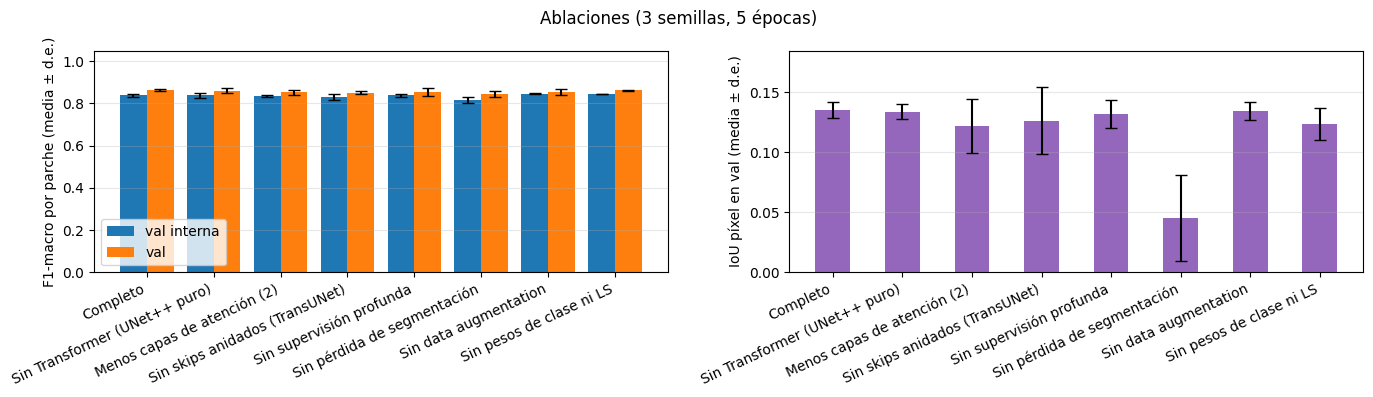

In [14]:
ABLATIONS = {
    "Completo": {},
    "Sin Transformer (UNet++ puro)": dict(trans_layers=0),
    f"Menos capas de atención ({max(1, TRANS_LAYERS // 2)})": dict(trans_layers=max(1, TRANS_LAYERS // 2)),
    "Sin skips anidados (TransUNet)": dict(nested=False),
    "Sin supervisión profunda": dict(deep_sup=False),
    "Sin pérdida de segmentación": dict(seg_weight=0.0),
    "Sin data augmentation": dict(augment=False),
    "Sin pesos de clase ni LS": dict(use_class_weights=False, label_smoothing=0.0),
}
abl = pd.DataFrame()
if TRANS_LAYERS == 0:
    ABLATIONS = {k: v for k, v in ABLATIONS.items() if "Transformer" not in k and "atención" not in k}
if not NESTED_SKIPS:
    ABLATIONS = {k: v for k, v in ABLATIONS.items() if "anidados" not in k and "supervisión" not in k}
if RUN_ABLATIONS:
    rows = []
    il = make_loader(ival_s, False, masks=True)
    for name, ov in ABLATIONS.items():
        for sd in ABLATION_SEEDS:
            m_, h_, inf_ = train_model(train_s, ival_s, epochs=ABLATION_EPOCHS, seed=sd, verbose=False,
                                       tag=f"{name} (seed {sd})", group="ablación", **ov)
            yv_, pv_, _, sv_, _ = predict_full(m_, il); yh_, ph_, _, sh_, _ = predict_full(m_, hold_loader)
            mv = compute_metrics(yv_, pv_); mh = compute_metrics(yh_, ph_)
            rows.append(dict(variante=name, seed=sd, parametros_M=sum(p.numel() for p in m_.parameters()) / 1e6,
                             val_interna_f1=mv["f1_macro"], val_f1=mh["f1_macro"], val_acc=mh["accuracy"],
                             val_bal_acc=mh["balanced_acc"], val_auc=mh["auc"], val_iou_pix=sh_["iou_pix"],
                             val_dice_pix=sh_["dice_pix"], mejor_epoca=inf_["best_epoch"], segundos=inf_["seconds"]))
            print(f"{name:38s} seed={sd:5d} | F1 val interna={mv['f1_macro']:.4f} | F1 {HOLDOUT_NAME}={mh['f1_macro']:.4f} | "
                  f"IoU píxel={sh_['iou_pix']:.4f} | {inf_['seconds']:.0f}s")
            del m_
            if DEVICE.type == "cuda": torch.cuda.empty_cache()
    abl = pd.DataFrame(rows); save_table(abl, "ablaciones_por_semilla")
    mc = ["val_interna_f1", "val_f1", "val_acc", "val_bal_acc", "val_auc", "val_iou_pix", "val_dice_pix"]
    g = abl.groupby("variante", sort=False)[mc]; mean, std = g.mean(), g.std(ddof=1).fillna(0)
    abl_summary = pd.DataFrame({c: [f"{mean.loc[v, c]:.4f} ± {std.loc[v, c]:.4f}" for v in mean.index] for c in mc}, index=mean.index)
    abl_summary["Δ F1 vs completo"] = [f"{mean.loc[v, 'val_f1'] - mean.iloc[0]['val_f1']:+.4f}" for v in mean.index]
    abl_summary["parámetros (M)"] = abl.groupby("variante", sort=False).parametros_M.first().round(2).values
    display(abl_summary); save_table(abl_summary.reset_index(), "ablaciones_resumen")

    fig, ax = plt.subplots(1, 2, figsize=(14, 4)); x = np.arange(len(mean))
    ax[0].bar(x - 0.2, mean.val_interna_f1, 0.4, yerr=std.val_interna_f1, capsize=4, label="val interna")
    ax[0].bar(x + 0.2, mean.val_f1, 0.4, yerr=std.val_f1, capsize=4, label=HOLDOUT_NAME)
    ax[0].set_ylabel("F1-macro por parche (media ± d.e.)"); ax[0].set_ylim(0, 1.05)
    ax[1].bar(x, mean.val_iou_pix, 0.5, yerr=std.val_iou_pix, capsize=4, color="tab:purple")
    ax[1].set_ylabel(f"IoU píxel en {HOLDOUT_NAME} (media ± d.e.)"); ax[1].set_ylim(0, max(0.05, (mean.val_iou_pix + std.val_iou_pix).max() * 1.2))
    for a in ax:
        a.set_xticks(x); a.set_xticklabels(mean.index, rotation=25, ha="right"); a.grid(axis="y", alpha=.3)
    ax[0].legend(); fig.suptitle(f"Ablaciones ({len(ABLATION_SEEDS)} semillas, {ABLATION_EPOCHS} épocas)")
    plt.tight_layout(); savefig("ablaciones"); plt.show()

## 10. Interpretabilidad y análisis de errores (R5)
### 10.1 Grad-CAM
$$\alpha_k^c = \frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}}, \qquad L^c_{\text{Grad-CAM}} = \text{ReLU}\Big(\sum_k \alpha_k^c A^k\Big)$$
sobre el ***bottleneck* tras el Transformer** (punto `model.bott`, 8×8 con parches de 128 px y `DEPTH = 4`), para la salida de **clasificación del parche**. Además de Grad-CAM, TransUNet++ produce su propio mapa de probabilidad de pérdida, que se evalúa en §10.2. El mapa se reescala al tamaño original del parche y se dibuja junto al **contorno de la pérdida real** (rojo).

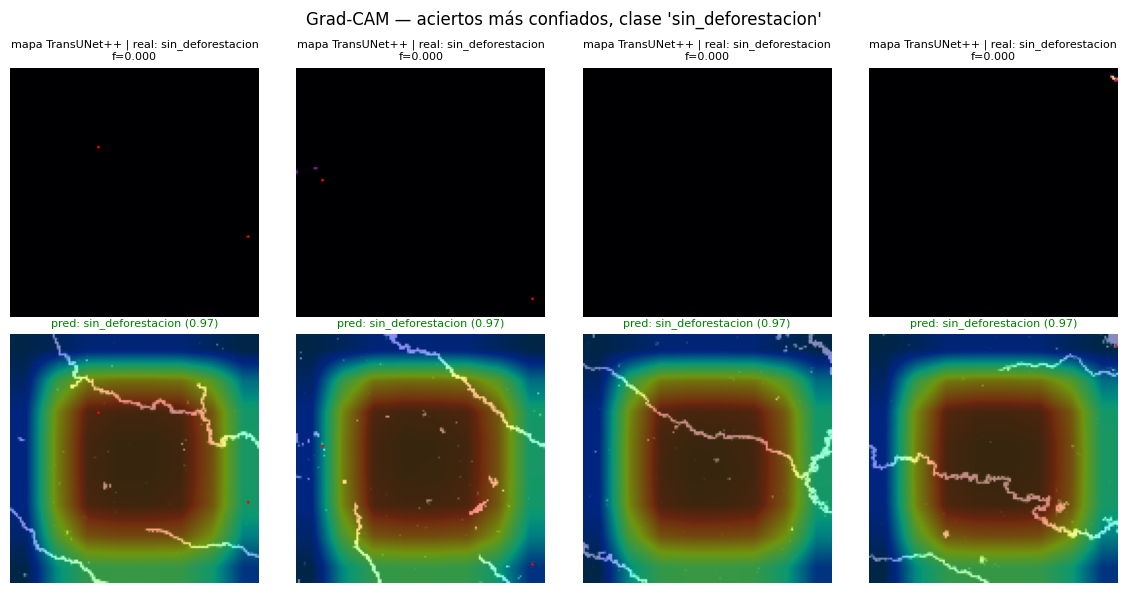

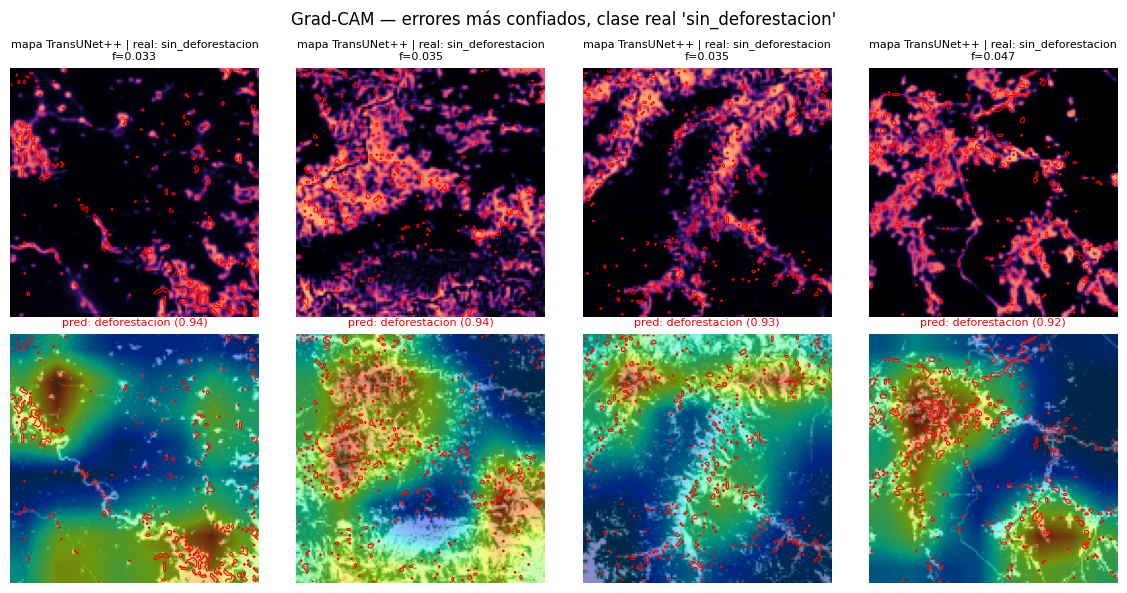

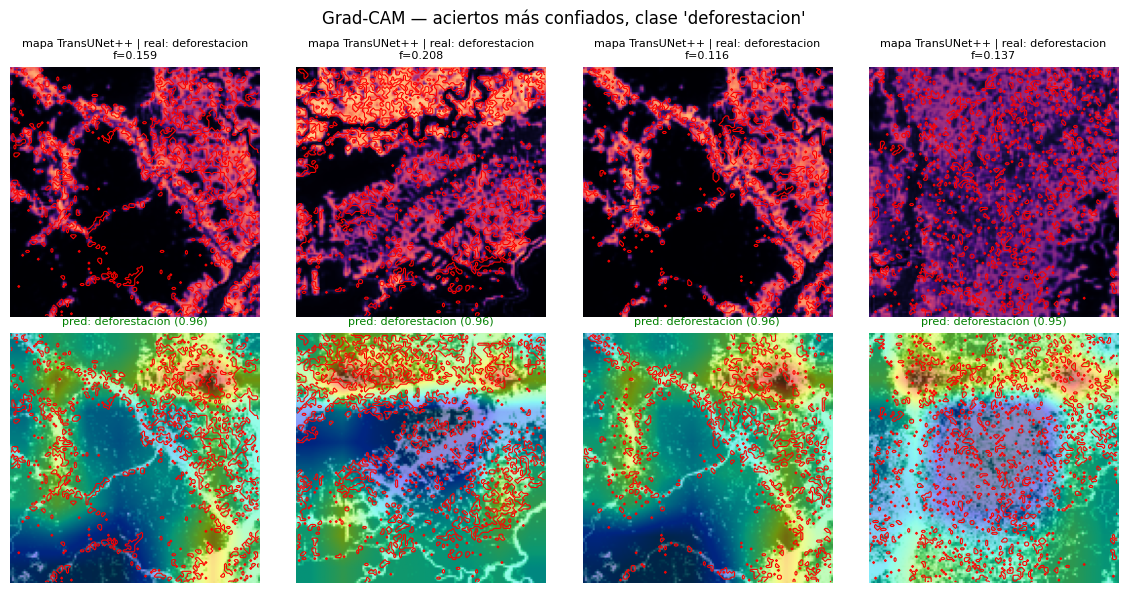

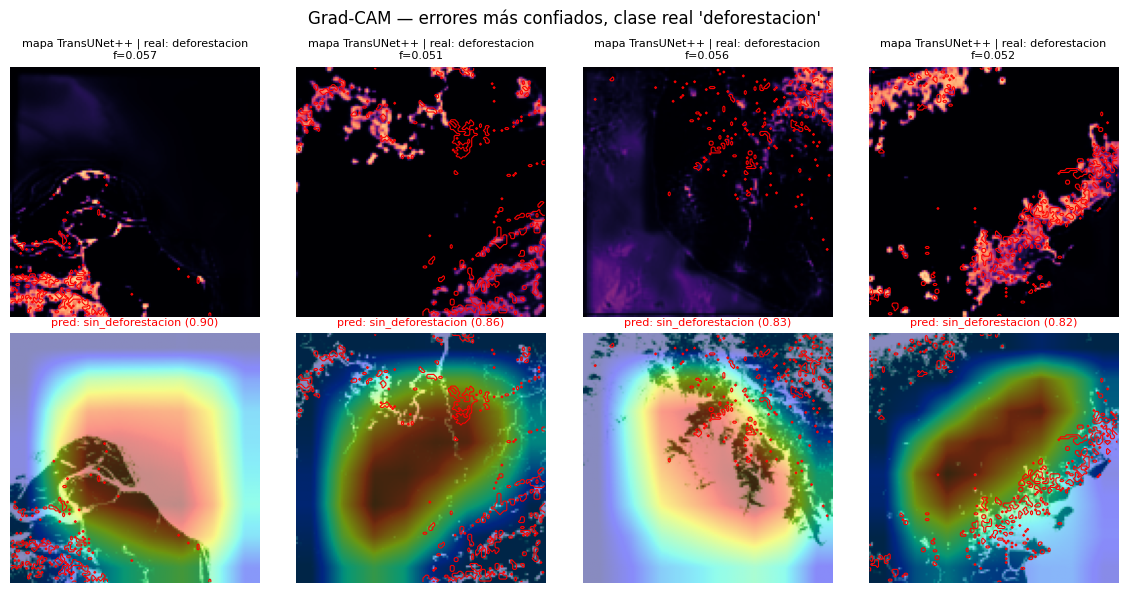

In [15]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.h = layer.register_forward_hook(self._fwd)
    def _fwd(self, module, inp, out):
        self.acts = out
        if out.requires_grad:
            out.register_hook(lambda g: setattr(self, "grads", g))
    def __call__(self, x, class_idx=None):
        self.model.eval()
        x = x.detach().to(DEVICE).clone().requires_grad_(True)
        logits = self.model(x)
        if class_idx is None: class_idx = logits.argmax(1)
        self.model.zero_grad(set_to_none=True)
        logits.gather(1, class_idx.view(-1, 1).to(DEVICE)).sum().backward()
        w = self.grads.mean((2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        mn, mx = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True)
        return ((cam - mn) / (mx - mn + 1e-8)).detach().cpu(), logits.softmax(1).detach().cpu()
    def remove(self): self.h.remove()

gradcam = GradCAM(model, model.bott)

def show_cams(df_rows, title, fname):
    if len(df_rows) == 0:
        print(f"(sin ejemplos para: {title})"); return
    n = len(df_rows)
    fig, axes = plt.subplots(2, n, figsize=(2.9 * n, 6.0), squeeze=False)
    for j, (_, r) in enumerate(df_rows.iterrows()):
        x, _, _ = hold_ds[pos_of[r.indice]]
        cam, _ = gradcam(x[None], torch.tensor([CLS2IDX[r.clase_predicha]]))
        img = rgb_image(HOLDOUT_NAME, r.indice); m = loss_mask(HOLDOUT_NAME, r.indice)
        axes[0, j].imshow(seg_map(r.indice), cmap="magma", vmin=0, vmax=1)
        axes[0, j].set_title(f"mapa TransUNet++ | real: {r.clase_real}\nf={r.frac_perdida:.3f}", fontsize=8)
        axes[1, j].imshow(img); axes[1, j].imshow(cam[0], cmap="jet", alpha=0.45)
        for a in axes[:, j]:
            if m is not None and m.any(): a.contour(m, levels=[0.5], colors="red", linewidths=0.8)
            a.axis("off")
        axes[1, j].set_title(f"pred: {r.clase_predicha} ({r.confianza:.2f})", fontsize=8, color="green" if r.correcto else "red")
    plt.suptitle(title); plt.tight_layout(); savefig(fname); plt.show()

for c in CLASSES:
    ok  = pred_df[(pred_df.clase_real == c) & pred_df.correcto].nlargest(4, "confianza")
    err = pred_df[(pred_df.clase_real == c) & ~pred_df.correcto].nlargest(4, "confianza")
    show_cams(ok,  f"Grad-CAM — aciertos más confiados, clase '{c}'", f"gradcam_aciertos_{c}")
    show_cams(err, f"Grad-CAM — errores más confiados, clase real '{c}'", f"gradcam_errores_{c}")

### 10.2 Localización: mapa de TransUNet++ y Grad-CAM vs. la pérdida real
Se comparan dos mapas con la máscara real en parches de `val` con pérdida: el **mapa de probabilidad de TransUNet++** (supervisado por píxel) y el **Grad-CAM** de la cabeza de clasificación (explica qué regiones usa la decisión del parche). Métricas:
- **Pointing game**: ¿el píxel de máxima activación cae dentro de la máscara? Se compara con el azar (= fracción de pérdida del parche).
- **Energía dentro de la máscara**: proporción de la "masa" de Grad-CAM sobre la máscara frente al área de la máscara (*lift* > 1 = mejor que el azar).
- **IoU** entre Grad-CAM binarizado (≥ 0.5) y la máscara.

,metodo,pointing_game,energia_en_mascara,iou,lift_mediano,azar (área),parches
0,Grad-CAM,0.035,0.0364,0.0316,1.0565,0.0255,200
1,Mapa TransUNet++,0.235,0.1092,0.0940,4.5333,0.0255,200


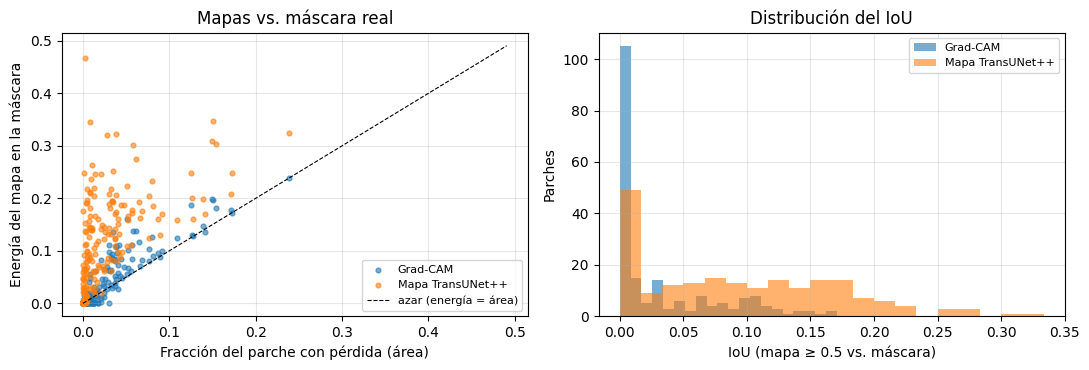

In [16]:
loc_df = pd.DataFrame()
if Y_KIND == "mascara" and "deforestacion" in CLS2IDX:
    POS = CLS2IDX["deforestacion"]
    cand = [t for t in holdout if FRAC[HOLDOUT_NAME][t[1]] > 0]
    cand = random.Random(SEED).sample(cand, min(GRADCAM_LOC_SAMPLES, len(cand)))
    rows = []
    for s, i, y in cand:
        x, _, _ = hold_ds[pos_of[i]]
        m = loss_mask(s, i); area = m.mean()
        maps = {"Grad-CAM": None, "Mapa TransUNet++": seg_map(i)}
        cam, prob = gradcam(x[None], torch.tensor([POS])); maps["Grad-CAM"] = cam[0].numpy()
        for metodo, mp in maps.items():
            mp_n = (mp - mp.min()) / (mp.max() - mp.min() + 1e-8)
            energy = (mp_n * m).sum() / (mp_n.sum() + 1e-8)
            b = mp >= 0.5; iou = (b & m).sum() / max(1, (b | m).sum())
            rows.append(dict(metodo=metodo, indice=i, frac_perdida=area, etiqueta=CLASSES[y], prob_deforestacion=float(prob[0, POS]),
                             pointing_hit=bool(m.flat[mp.argmax()]), energia_en_mascara=energy,
                             lift_energia=energy / max(area, 1e-8), iou=iou))
    loc_all = pd.DataFrame(rows); loc_all.to_csv(OUT / "tables" / "gradcam_localizacion_detalle.csv", index=False)
    azar = loc_all.groupby("metodo").frac_perdida.mean()
    loc_sum = loc_all.groupby("metodo").agg(pointing_game=("pointing_hit", "mean"), energia_en_mascara=("energia_en_mascara", "mean"),
                                            iou=("iou", "mean"), lift_mediano=("lift_energia", "median")).reset_index()
    loc_sum["azar (área)"] = loc_sum.metodo.map(azar); loc_sum["parches"] = len(cand)
    display(loc_sum.round(4)); save_table(loc_sum, "gradcam_localizacion")
    loc_df = loc_all[loc_all.metodo == "Mapa TransUNet++"].copy()   # mapa TransUNet++ (usado en el resumen y en MLflow)

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for metodo, d in loc_all.groupby("metodo"):
        ax[0].scatter(d.frac_perdida, d.energia_en_mascara, s=12, alpha=.6, label=metodo)
        ax[1].hist(d.iou, bins=20, alpha=.6, label=metodo)
    lim = max(loc_all.frac_perdida.max(), loc_all.energia_en_mascara.max()) * 1.05
    ax[0].plot([0, lim], [0, lim], "k--", lw=.8, label="azar (energía = área)")
    ax[0].set_xlabel("Fracción del parche con pérdida (área)"); ax[0].set_ylabel("Energía del mapa en la máscara")
    ax[0].set_title("Mapas vs. máscara real"); ax[0].legend(fontsize=8)
    ax[1].set_xlabel("IoU (mapa ≥ 0.5 vs. máscara)"); ax[1].set_ylabel("Parches"); ax[1].set_title("Distribución del IoU"); ax[1].legend(fontsize=8)
    for a in ax: a.grid(alpha=.3)
    plt.tight_layout(); savefig("gradcam_localizacion"); plt.show()
else:
    print("Y no es una máscara de pérdida: se omite la evaluación de localización.")

### 10.3 Fidelidad de Grad-CAM: prueba de borrado
Se ocultan (valor 0 = media de `train` tras estandarizar) fracciones crecientes de píxeles, primero los más relevantes según Grad-CAM y, como control, al azar. Si la probabilidad cae más rápido con Grad-CAM (menor AUC), el mapa es **fiel** a lo que usa el modelo.

,metodo,auc_borrado,d_e,imagenes
0,Grad-CAM,0.6031,0.1514,64
1,Aleatorio,0.6361,0.1276,64


Grad-CAM más fiel que el azar en 65.6% de los parches


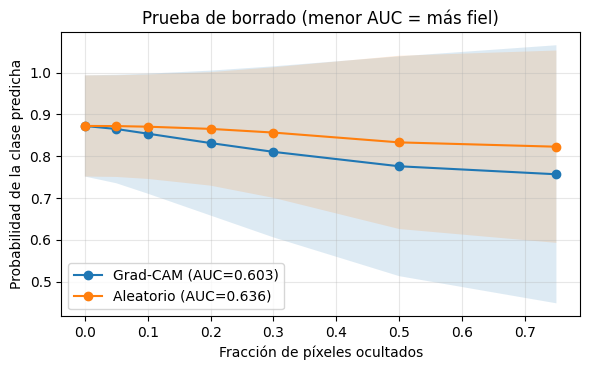

In [17]:
FRACS = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75]

@torch.no_grad()
def deletion_curve(x, cam, cls, mode, gen):
    Hh, Ww = cam.shape; n = Hh * Ww
    order = torch.argsort(cam.flatten(), descending=True) if mode == "cam" else torch.randperm(n, generator=gen)
    xs = []
    for f in FRACS:
        k = int(f * n); xm = x.clone()
        if k > 0:
            mask = torch.zeros(n, dtype=torch.bool); mask[order[:k]] = True
            xm = xm.masked_fill(mask.view(1, 1, Hh, Ww), 0.0)
        xs.append(xm)
    return model.eval()(torch.cat(xs).to(DEVICE)).softmax(1)[:, cls].cpu().numpy()

gen = torch.Generator().manual_seed(SEED)
sub = random.Random(SEED).sample(range(len(holdout)), min(GRADCAM_FIDELITY_SAMPLES, len(holdout)))
curves = {"cam": [], "random": []}
for j in sub:
    x = hold_ds[j][0][None]
    cam, prob = gradcam(x); cls = int(prob.argmax(1))
    for mode in curves:
        curves[mode].append(deletion_curve(x, cam[0], cls, mode, gen))
curves = {k: np.array(v) for k, v in curves.items()}
auc_del = {k: _trapz(v.mean(0), FRACS) for k, v in curves.items()}
per_img = {k: np.array([_trapz(c, FRACS) for c in v]) for k, v in curves.items()}
fid = pd.DataFrame([dict(metodo="Grad-CAM", auc_borrado=auc_del["cam"], d_e=per_img["cam"].std()),
                    dict(metodo="Aleatorio", auc_borrado=auc_del["random"], d_e=per_img["random"].std())])
fid["imagenes"] = len(sub); display(fid.round(4)); save_table(fid, "fidelidad_gradcam")
print(f"Grad-CAM más fiel que el azar en {(per_img['cam'] < per_img['random']).mean():.1%} de los parches")

fig, ax = plt.subplots(figsize=(6, 3.8))
for k, lbl in [("cam", "Grad-CAM"), ("random", "Aleatorio")]:
    mu, sd = curves[k].mean(0), curves[k].std(0)
    ax.plot(FRACS, mu, "o-", label=f"{lbl} (AUC={auc_del[k]:.3f})"); ax.fill_between(FRACS, mu - sd, mu + sd, alpha=.15)
ax.set_xlabel("Fracción de píxeles ocultados"); ax.set_ylabel("Probabilidad de la clase predicha")
ax.set_title("Prueba de borrado (menor AUC = más fiel)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); savefig("fidelidad_gradcam"); plt.show()
gradcam.remove()

### 10.4 Calibración y confianza

ECE = 0.0326


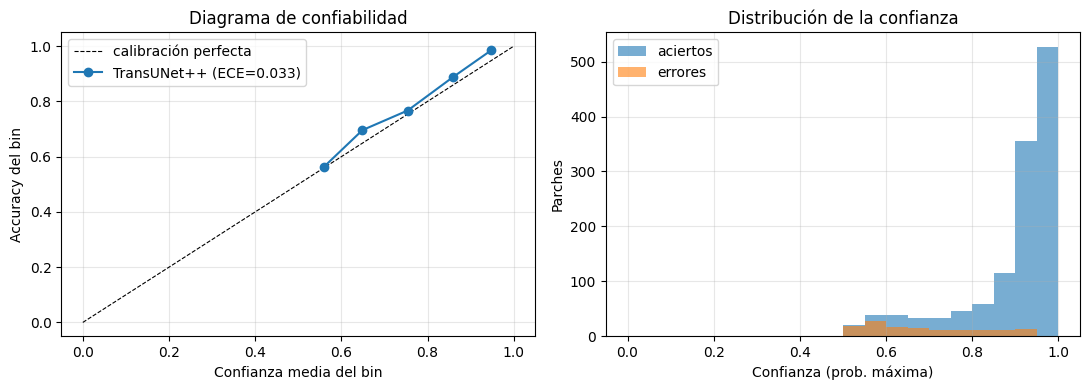

In [18]:
def ece_score(conf, correct, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1); e, rows = 0.0, []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean()); rows.append((conf[m].mean(), correct[m].mean(), m.sum()))
    return e, np.array(rows)

conf, correct = p_hold.max(1), (pred_hold == y_hold).astype(float)
ece, rel = ece_score(conf, correct); print(f"ECE = {ece:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([0, 1], [0, 1], "k--", lw=.8, label="calibración perfecta")
ax[0].plot(rel[:, 0], rel[:, 1], "o-", label=f"{ARCH_LABEL} (ECE={ece:.3f})")
ax[0].set_xlabel("Confianza media del bin"); ax[0].set_ylabel("Accuracy del bin"); ax[0].set_title("Diagrama de confiabilidad"); ax[0].legend()
ax[1].hist(conf[correct == 1], bins=20, range=(0, 1), alpha=.6, label="aciertos")
ax[1].hist(conf[correct == 0], bins=20, range=(0, 1), alpha=.6, label="errores")
ax[1].set_xlabel("Confianza (prob. máxima)"); ax[1].set_ylabel("Parches"); ax[1].set_title("Distribución de la confianza"); ax[1].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); savefig("calibracion"); plt.show()

### 10.5 Espacio latente (t-SNE de los *embeddings* del *bottleneck*)

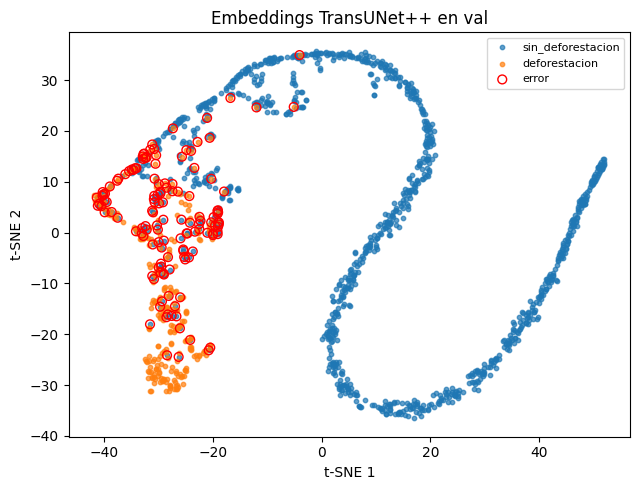

In [19]:
from sklearn.manifold import TSNE
E, yE = extract_features(Embedder(model), holdout)
n_max = min(2000, len(E)); sel_i = np.random.RandomState(SEED).choice(len(E), n_max, replace=False)
Z = TSNE(n_components=2, perplexity=min(30, max(5, n_max // 4)), init="pca", random_state=SEED).fit_transform(E[sel_i])
err_sel = pred_hold[sel_i] != y_hold[sel_i]
fig, ax = plt.subplots(figsize=(6.5, 5))
for k, c in enumerate(CLASSES):
    m = yE[sel_i] == k; ax.scatter(Z[m, 0], Z[m, 1], s=10, alpha=.7, label=c)
ax.scatter(Z[err_sel, 0], Z[err_sel, 1], s=40, facecolors="none", edgecolors="red", lw=1, label="error")
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2"); ax.set_title(f"Embeddings {ARCH_LABEL} en {HOLDOUT_NAME}"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("tsne_embeddings"); plt.show()

### 10.6 Análisis sistemático de errores
¿Los errores se concentran cerca del umbral $\tau$ (etiquetas ambiguas), en parches con muchos píxeles inválidos (nubes, sin dato) o con poca pérdida visible?

,clase_real,n,tasa_error
0,deforestacion,297,0.1414
1,sin_deforestacion,1105,0.0851


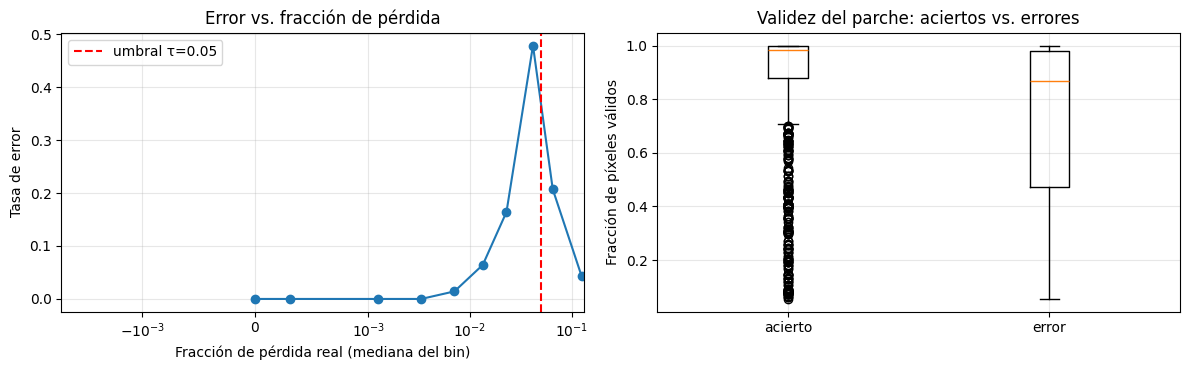

Tasa de error cerca del umbral (|f-τ|<τ): 0.110 | lejos del umbral: 0.024


In [20]:
ea = pred_df.copy()
err_by_class = ea.groupby("clase_real").agg(n=("correcto", "size"), tasa_error=("correcto", lambda s: 1 - s.mean())).reset_index()
display(err_by_class.round(4)); save_table(err_by_class, "tasa_error_por_clase")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
if Y_KIND != "clase":
    edges = np.unique(np.quantile(ea.frac_perdida, np.linspace(0, 1, 11)))
    if len(edges) > 2:
        ea["bin_frac"] = pd.cut(ea.frac_perdida, edges, include_lowest=True, duplicates="drop")
        eb = ea.groupby("bin_frac", observed=True).agg(tasa_error=("correcto", lambda s: 1 - s.mean()), n=("correcto", "size"),
                                                        centro=("frac_perdida", "median")).reset_index()
        ax[0].plot(eb.centro, eb.tasa_error, "o-")
        ax[0].axvline(FRAC_THRESHOLD, c="r", ls="--", label=f"umbral τ={FRAC_THRESHOLD}")
        ax[0].set_xscale("symlog", linthresh=1e-3); ax[0].legend()
        save_table(eb.astype({"bin_frac": str}), "error_por_fraccion")
    ax[0].set_xlabel("Fracción de pérdida real (mediana del bin)"); ax[0].set_ylabel("Tasa de error"); ax[0].set_title("Error vs. fracción de pérdida")
data = [ea.loc[ea.correcto, "frac_valida"], ea.loc[~ea.correcto, "frac_valida"]]
if len(data[1]) and len(data[0]):
    ax[1].boxplot(data); ax[1].set_xticks([1, 2]); ax[1].set_xticklabels(["acierto", "error"])
ax[1].set_ylabel("Fracción de píxeles válidos"); ax[1].set_title("Validez del parche: aciertos vs. errores")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); savefig("analisis_errores"); plt.show()

near = (ea.frac_perdida - FRAC_THRESHOLD).abs() < FRAC_THRESHOLD if Y_KIND != "clase" else pd.Series(False, index=ea.index)
if near.any():
    print(f"Tasa de error cerca del umbral (|f-τ|<τ): {1 - ea[near].correcto.mean():.3f} | lejos del umbral: {1 - ea[~near].correcto.mean():.3f}")
ea.to_csv(OUT / "tables" / "analisis_errores_detalle.csv", index=False)

## 11. Costo computacional (R6)

In [21]:
try:
    import psutil; ram = f"{psutil.virtual_memory().total / 1e9:.1f} GB"
except ImportError:
    ram = "N/D"
hw = {"GPU": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "ninguna (CPU)",
      "VRAM": f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB" if DEVICE.type == "cuda" else "N/D",
      "CPU": platform.processor() or platform.machine(), "núcleos CPU": os.cpu_count(), "RAM": ram,
      "Python": platform.python_version(), "PyTorch": torch.__version__, "CUDA": torch.version.cuda or "N/D"}
display(pd.Series(hw, name="valor").to_frame())

comp_log = pd.DataFrame(COMPUTE_LOG)
by_group = comp_log.groupby("grupo", sort=False).segundos.sum().to_frame(); by_group["horas"] = by_group.segundos / 3600
by_group.loc["TOTAL"] = by_group.sum(); total_h = by_group.loc["TOTAL", "horas"]
energy = GPU_POWER_W * total_h / 1000 if DEVICE.type == "cuda" else float("nan")
display(by_group.round(4))

n_params = sum(p.numel() for p in model.parameters())
model.eval()
xb1 = torch.randn(1, C_IN, H, W, device=DEVICE); xbB = torch.randn(BATCH_SIZE, C_IN, H, W, device=DEVICE)
def bench(x, reps=20):
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        for _ in range(3): model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t = time.time()
        for _ in range(reps): model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t) / reps
lat1, latB = bench(xb1), bench(xbB)
cost = pd.DataFrame([
    (f"Parámetros {ARCH_LABEL}", f"{n_params / 1e6:.2f} M"),
    ("Tiempo entrenamiento modelo principal", f"{by_group.loc['principal', 'horas'] if 'principal' in by_group.index else 0:.3f} h"),
    ("Tiempo total de entrenamientos", f"{total_h:.3f} h"),
    ("Horas de GPU aproximadas", f"{total_h:.3f} h" if DEVICE.type == "cuda" else "0 (CPU)"),
    ("Energía estimada (GPU)", f"{energy:.3f} kWh (supone {GPU_POWER_W} W)"),
    ("CO₂ estimado", f"{energy * GRID_KG_CO2_PER_KWH:.3f} kg (factor {GRID_KG_CO2_PER_KWH} kg/kWh)"),
    ("Latencia de inferencia (1 parche)", f"{lat1 * 1000:.1f} ms"),
    (f"Throughput (lote {BATCH_SIZE})", f"{BATCH_SIZE / latB:.0f} parches/s")], columns=["concepto", "valor"])
display(cost); save_table(cost, "costo_computacional"); save_table(comp_log, "costo_por_etapa")
save_table(pd.Series(hw).to_frame("valor").reset_index().rename(columns={"index": "componente"}), "hardware")

,valor
GPU,Tesla T4
VRAM,15.6 GB
CPU,x86_64
núcleos CPU,4
RAM,33.7 GB
Python,3.13.16
PyTorch,2.11.0+cu130
CUDA,13.0


,segundos,horas
grupo,,
principal,922.0134,0.2561
línea base,196.5306,0.0546
ablación,9674.6345,2.6874
TOTAL,10793.1784,2.9981


,concepto,valor
0,Parámetros TransUNet++,12.61 M
1,Tiempo entrenamiento modelo principal,0.256 h
2,Tiempo total de entrenamientos,2.998 h
3,Horas de GPU aproximadas,2.998 h
4,Energía estimada (GPU),0.210 kWh (supone 70 W)
5,CO₂ estimado,0.052 kg (factor 0.25 kg/kWh)
6,Latencia de inferencia (1 parche),10.8 ms
7,Throughput (lote 32),286 parches/s


## 12. Resumen y archivos para el repositorio

In [22]:
summary = {
    "datos": str(DATA_DIR), "layout": LAYOUT, "parche": [int(H), int(W)], "bandas": BAND_NAMES,
    "entrada": [BAND_NAMES[i] for i in CH_ORDER], "excluidas": [BAND_NAMES[i] for i in EXCLUDED], "tipo_Y": Y_KIND, "umbral_frac": FRAC_THRESHOLD, "clases": CLASSES,
    "n_train": len(train_s), "n_val_interna": len(ival_s), "conjunto_evaluacion": HOLDOUT_NAME, "n_evaluacion": len(holdout),
    "modelo": ARCH_LABEL, "parametros_M": round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
    "transunetpp": {"depth": DEPTH, "base_ch": BASE_CH, "trans_layers": TRANS_LAYERS, "embed_dim": EMBED_DIM,
                    "heads": N_HEADS, "nested": NESTED_SKIPS, "deep_sup": DEEP_SUPERVISION, "dice": USE_DICE},
    ARCH: {k: round(float(v), 4) for k, v in m_hold.items()},
    "segmentacion": {k: round(float(v), 4) for k, v in seg_hold.items()}, "mejor_epoca": info["best_epoch"],
    "lineas_base_f1": {r["modelo"]: round(float(r["f1_macro"]), 4) for r in baseline_rows},
    "ece": round(float(ece), 4), "gradcam_auc_borrado": {k: round(float(v), 4) for k, v in auc_del.items()},
    "horas_computo_total": round(float(total_h), 4), "hardware": hw}
if len(loc_df):
    summary["localizacion"] = {r.metodo: {"pointing_game": round(float(r.pointing_game), 4), "iou": round(float(r.iou), 4)}
                               for r in loc_sum.itertuples()}
if len(abl):
    summary["ablaciones_f1_val_media"] = abl.groupby("variante", sort=False).val_f1.mean().round(4).to_dict()
(OUT / "resumen.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))

best_base = max([r for r in baseline_rows if "propuesto" not in r["modelo"]], key=lambda r: r["f1_macro"], default=None)
txt = (f"Sobre el conjunto {HOLDOUT_NAME} ({len(holdout)} parches de {H}×{W} px y {C_IN} capas), la {ARCH_LABEL} "
       f"alcanzó por parche un F1-macro de {m_hold['f1_macro']:.3f}, accuracy de {m_hold['accuracy']:.3f}, balanced accuracy de "
       f"{m_hold['balanced_acc']:.3f} y AUC-ROC de {m_hold['auc']:.3f}; en segmentación obtuvo IoU de {seg_hold['iou_pix']:.3f} "
       f"y Dice de {seg_hold['dice_pix']:.3f}")
if best_base: txt += f", frente a {best_base['f1_macro']:.3f} de la mejor línea base ({best_base['modelo']})"
txt += f". El ECE fue {ece:.3f}."
if len(loc_df):
    _u = loc_df
    txt += (f" El máximo del mapa de TransUNet++ cayó dentro de la pérdida real en el {_u.pointing_hit.mean():.1%} de los parches "
            f"con deforestación (azar: {_u.frac_perdida.mean():.1%}).")
txt += (f" En la prueba de borrado, Grad-CAM obtuvo un AUC de {auc_del['cam']:.3f} frente a {auc_del['random']:.3f} del azar. "
        f"El entrenamiento total requirió {total_h:.2f} h en {hw['GPU']}.")
print(txt); (OUT / "parrafo_resultados.txt").write_text(txt)

from importlib.metadata import version, PackageNotFoundError
req = []
for p in ["torch", "torchvision", "numpy", "pandas", "scikit-learn", "matplotlib"]:
    try: req.append(f"{p}=={version(p)}")
    except PackageNotFoundError: pass
(WORK / "requirements.txt").write_text("\n".join(req) + "\n"); print("\n".join(req))

import shutil
shutil.make_archive(str(WORK / f"results_{ARCH}"), "zip", OUT)
print("Archivos en results/:", len([p for p in OUT.rglob("*") if p.is_file()]))
print(f"Descarga results_{ARCH}.zip y checkpoints/best_{ARCH}.pt desde el panel Output (/kaggle/working).")

Sobre el conjunto val (1402 parches de 128×128 px y 31 capas), la TransUNet++ alcanzó por parche un F1-macro de 0.863, accuracy de 0.903, balanced accuracy de 0.887 y AUC-ROC de 0.963; en segmentación obtuvo IoU de 0.145 y Dice de 0.253, frente a 0.870 de la mejor línea base (Random Forest (estadísticos por banda)). El ECE fue 0.033. El máximo del mapa de TransUNet++ cayó dentro de la pérdida real en el 23.5% de los parches con deforestación (azar: 2.6%). En la prueba de borrado, Grad-CAM obtuvo un AUC de 0.603 frente a 0.636 del azar. El entrenamiento total requirió 3.00 h en Tesla T4.
torch==2.11.0+cu130
torchvision==0.26.0+cu130
numpy==2.1.3
pandas==2.3.3
scikit-learn==1.6.1
matplotlib==3.10.0
Archivos en results/: 57
Descarga results_transunetpp.zip y checkpoints/best_transunetpp.pt desde el panel Output (/kaggle/working).


## 13. Discusión, limitaciones, sesgos y uso responsable
Completa con los números de las celdas anteriores (§V del artículo):

**Por qué funciona (o no).**
- *Completo* vs. *Sin Transformer (UNet++ puro)*: mide el aporte del **contexto global**; la deforestación depende de relaciones de largo alcance dentro del parche (vías, ríos, frontera agrícola), que la auto-atención puede capturar mejor que convoluciones locales.
- *Menos capas de atención*: si casi no cambia, un Transformer más pequeño basta (menor costo, §11).
- *Completo* vs. *Sin skips anidados (TransUNet)*: mide el aporte del decoder denso de UNet++, sobre todo en la segmentación (IoU/Dice) y en bordes finos.
- *Sin supervisión profunda*: supervisar los nodos intermedios suele estabilizar el entrenamiento y mejorar la segmentación con pocos datos.
- *Sin pérdida de segmentación*: si la supervisión por píxel mejora el F1 del parche, la tarea auxiliar actúa como regularizador.
- Si el **Random Forest** queda cerca o por encima, buena parte de la señal está en estadísticos por capa (datos tipo tabla) y el aporte de TransUNet++ está en el contexto espacial y en la delimitación del área; discútelo con honestidad.
- La localización (§10.2) compara el mapa de TransUNet++ con Grad-CAM: el mapa supervisado debería localizar mucho mejor; si Grad-CAM también cae en la pérdida, la cabeza de clasificación usa la evidencia correcta y no atajos.

**Casos de error.** §10.6: si el error se concentra cerca de $\tau$, gran parte es **ambigüedad de la etiqueta** (parches con muy poca pérdida), no falla del modelo. Revisa también parches con muchos píxeles inválidos.

**Limitaciones.**
- La etiqueta por parche depende del umbral $\tau$ (decisión de diseño); reporta la sensibilidad a $\tau$ si hay tiempo.
- La entrada son capas geoespaciales de un solo momento *t*; incorporar series temporales (p. ej. imágenes Sentinel-2/Landsat de varias fechas) es trabajo futuro.
- La red se entrena desde cero; los Transformers suelen necesitar muchos datos o preentrenamiento, por lo que un encoder preentrenado o un modelo fundacional de observación de la Tierra podría mejorar (trabajo futuro).
- Se excluyeron las capas de pérdida por prudencia; si `Y` es pérdida futura, incluir la pérdida histórica es legítimo y probablemente mejora el desempeño (experimento aparte).
- La distribución de clases cambia entre `train` (≈ 50 % deforestación, muestreo "cerca de pérdida") y `val`/`test` (≈ 20 %): las métricas dependientes de la prevalencia (precisión, F1) cambiarán al desplegar.
- **Autocorrelación espacial:** si `train`, `val` y `test` provienen de zonas contiguas, el desempeño puede estar sobreestimado; el control MD5 solo detecta duplicados exactos.
- Un sensor, fechas y región limitados; posibles errores en las máscaras de referencia.

**Sesgos de los datos.** Cobertura geográfica y estacional, nubosidad, tipo de bosque y proporción de clases distinta de la real (la deforestación es un evento raro → la precisión cae al desplegar).

**Impacto y uso responsable.** Útil para priorizar alertas de monitoreo forestal, pero un **falso positivo** puede señalar injustamente a comunidades o productores y un **falso negativo** ocultar tala ilegal. No debe usarse como evidencia única: requiere verificación de campo, supervisión humana y recalibración antes de usarse en otra región.

**Costo ambiental.** Reporta horas de GPU y CO₂ de §11 (con la fuente del factor de emisión).

**Declaración de uso de IA.** El enunciado exige declarar qué asistente de IA se usó y para qué, y que todos los resultados provienen de ejecuciones propias.

## 14. MLFlow Tracking y Exportación Joblib
Guardamos el experimento en MLFlow y exportamos el modelo en formato joblib para uso posterior.

In [23]:
# ===================== 15. MODELO COMPILADO (joblib) + REGISTRO EN MLFLOW =====================
# Genera UN archivo autocontenido para desplegar como API: pesos + código de la arquitectura +
# normalización + orden de canales + clases. Luego registra el run en MLflow por su API REST
# (sin instalar paquetes: no modifica las librerías de la sesión).
MLFLOW_URI        = "http://208.68.37.250:5000"
MLFLOW_EXPERIMENT = "Deforestacion"
MODELO            = None          # nombre del run; None = ARCH_LABEL
EQUIPO            = "Equipo7"
SUBIR_JOBLIB      = True          # subir el joblib como artefacto del run

import ast, json, math, re, time, warnings, joblib, requests
from pathlib import Path
G = globals()
MODELO = MODELO or G.get("ARCH_LABEL") or G.get("ARCH") or type(model).__name__

# ---------- 1) Código de la arquitectura: definiciones de la celda donde vive build_model ----------
def _define_build_model(src):                                    # ¿la celda DEFINE build_model? (no basta con mencionarla)
    try: return any(isinstance(n, ast.FunctionDef) and n.name == "build_model" for n in ast.parse(src).body)
    except SyntaxError: return False
_cells = [c for c in G.get("In", []) if _define_build_model(c)]
assert _cells, "No se encontró la celda que define build_model (ejecuta el cuaderno completo antes de esta celda)."
_src = _cells[-1]
_keep = [n for n in ast.parse(_src).body if isinstance(n, (ast.Import, ast.ImportFrom, ast.ClassDef, ast.FunctionDef,
                                                             ast.Assign, ast.AnnAssign))]
MODEL_SOURCE = "\n\n".join(ast.get_source_segment(_src, n) for n in _keep)
print("Código de la arquitectura tomado de la celda que empieza con:", _src.strip().splitlines()[0][:80])

# ---------- 2) Valores de configuración que usa ese código (solo tipos simples) ----------
def _simple(v):
    if isinstance(v, (bool, int, float, str, type(None))): return True
    if isinstance(v, (list, tuple)): return all(_simple(x) for x in v)
    if isinstance(v, dict): return all(isinstance(k, str) and _simple(x) for k, x in v.items())
    return False
SNAPSHOT = {k: (list(v) if isinstance(v, tuple) else v) for k, v in G.items()
            if k.isupper() and not k.startswith("_") and _simple(v)}
SNAPSHOT.update({"C_IN": int(C_IN), "H": int(H), "W": int(W), "K": int(K)})

# ---------- 3) Argumentos para reconstruir el modelo (sin descargar pesos preentrenados) ----------
import inspect
_bk = {}
for name, p in inspect.signature(build_model).parameters.items():
    if name == "num_classes": continue
    if name == "pretrained": _bk[name] = False; continue        # los pesos entrenados van en el joblib
    if name == "c_in": _bk[name] = int(C_IN); continue

# ---------- 4) Bundle joblib ----------
EXPORT_DIR = OUT / "export"; EXPORT_DIR.mkdir(parents=True, exist_ok=True)
BUNDLE = {
    "formato": "deforestacion-bundle-v1",
    "arch": G.get("ARCH"), "arch_label": G.get("ARCH_LABEL"), "classes": list(CLASSES),
    "ch_order": [int(c) for c in CH_ORDER], "band_names": list(BAND_NAMES),
    "mean_all": np.asarray(MEAN_ALL, np.float32), "std_all": np.asarray(STD_ALL, np.float32),
    "layout": LAYOUT, "input_shape": [int(C), int(H), int(W)],          # forma del parche crudo (antes de elegir canales)
    "frac_threshold": float(FRAC_THRESHOLD), "build_kwargs": _bk,
    "model_source": MODEL_SOURCE, "config": SNAPSHOT,
    "state_dict": {k: v.detach().cpu().numpy() for k, v in model.state_dict().items()},
    "metricas_val": {k: float(v) for k, v in {**G.get("m_hold", {}), **G.get("seg_hold", {})}.items()},
    "creado": time.strftime("%Y-%m-%d %H:%M:%S"),
}
BUNDLE_PATH = EXPORT_DIR / f"{G.get('ARCH', 'modelo')}_bundle.joblib"
joblib.dump(BUNDLE, BUNDLE_PATH, compress=3)
print(f"Joblib: {BUNDLE_PATH}  ({BUNDLE_PATH.stat().st_size / 1e6:.1f} MB)")

# ---------- 5) Cargador independiente (el mismo código sirve en la API) ----------
def cargar_bundle(path, device="cpu"):
    import numpy as np, math, random, torch, torch.nn as nn, torch.nn.functional as F
    from pathlib import Path
    from collections import Counter
    b = joblib.load(path)
    ns = {"np": np, "math": math, "random": random, "torch": torch, "nn": nn, "F": F, "Path": Path, "Counter": Counter,
          **b["config"]}
    try:
        from torchvision import models; ns["models"] = models
    except ImportError:
        pass
    errores = []
    for node in ast.parse(b["model_source"]).body:                   # cada definición por separado
        try: exec(compile(ast.Module([node], []), "<modelo>", "exec"), ns)
        except Exception as e: errores.append(f"línea {node.lineno}: {type(e).__name__}: {e}")
    if "build_model" not in ns:
        raise RuntimeError("El joblib no contiene la definición de build_model. Errores al cargar el código:\n"
                           + "\n".join(errores[:10]))
    m = ns["build_model"](len(b["classes"]), **b["build_kwargs"])
    m.load_state_dict({k: torch.from_numpy(v) for k, v in b["state_dict"].items()})
    return m.to(device).eval(), b

def predecir(m, b, x_raw, device="cpu"):
    # x_raw: parche crudo con la disposición b["layout"] (p. ej. C×H×W) y TODAS las capas originales
    import numpy as np, torch
    a = np.asarray(x_raw, dtype=np.float32)
    a = a.transpose(2, 0, 1) if b["layout"] == "NHWC" else (a[None] if b["layout"] == "NHW" else a)
    ch = b["ch_order"]
    x = np.nan_to_num((a[ch] - b["mean_all"][ch, None, None]) / b["std_all"][ch, None, None])
    with torch.no_grad():
        xt = torch.from_numpy(x)[None].to(device)
        out = m.forward_all(xt) if hasattr(m, "forward_all") else (m(xt), None)
    cls, seg = out[0], out[1]
    res = {"probabilidades": dict(zip(b["classes"], cls.softmax(1)[0].cpu().numpy().round(4).tolist()))}
    res["clase"] = max(res["probabilidades"], key=res["probabilidades"].get)
    if seg is not None:
        mapa = torch.sigmoid(seg)[0, 0].cpu().numpy()
        res["fraccion_perdida_predicha"] = round(float((mapa > 0.5).mean()), 4)
        res["mapa_probabilidad"] = mapa                                # H×W (convertir a lista para JSON)
    return res

# Verificación: el modelo recargado desde el joblib da lo mismo que el del cuaderno
m_chk, b_chk = cargar_bundle(BUNDLE_PATH)
x_raw = np.asarray(arr(HOLDOUT_NAME)[holdout[0][1]])
p_new = predecir(m_chk, b_chk, x_raw)["probabilidades"]
p_ref = predecir(model.to("cpu").eval(), BUNDLE, x_raw)["probabilidades"]; model.to(DEVICE)
dif = max(abs(p_new[c] - p_ref[c]) for c in p_new)
print(f"Verificación joblib → modelo: max|Δ prob| = {dif:.2e}  {'OK' if dif < 1e-4 else 'REVISAR'} | ejemplo: {p_new}")
del m_chk

# ---------- 6) Registro en MLflow por REST ----------
API = MLFLOW_URI.rstrip("/") + "/api/2.0/mlflow"
def _post(ep, payload):
    r = requests.post(f"{API}/{ep}", json=payload, timeout=60)
    if r.status_code != 200: raise RuntimeError(f"{ep}: HTTP {r.status_code} {r.text[:300]}")
    return r.json()
def _k(s):
    s = str(s).replace("Δ", "delta").replace("±", "pm").encode("ascii", "ignore").decode()
    return re.sub(r"[^0-9A-Za-z_\-\. /]+", "_", s).strip("_")[:250]
def _num(v):
    try: v = float(v); return v if math.isfinite(v) else None
    except (TypeError, ValueError): return None

try:
    r = requests.get(f"{API}/experiments/get-by-name", params={"experiment_name": MLFLOW_EXPERIMENT}, timeout=30)
    exp_id = r.json()["experiment"]["experiment_id"] if r.status_code == 200 else \
             _post("experiments/create", {"name": MLFLOW_EXPERIMENT})["experiment_id"]
    now = int(time.time() * 1000)
    run_name = f"{MODELO}_ep{G.get('EPOCHS', 'NA')}_{time.strftime('%Y%m%d-%H%M')}"
    tags = {"mlflow.runName": run_name, "modelo": MODELO, "equipo": EQUIPO, "curso": "MIA-203",
            "dataset": "gerardobarzola/dataset-deforestacion", "conjunto_eval": G.get("HOLDOUT_NAME", "val"),
            "gpu": (G.get("hw") or {}).get("GPU", str(G.get("DEVICE", "N/D"))), "joblib_local": str(BUNDLE_PATH)}
    run = _post("runs/create", {"experiment_id": exp_id, "run_name": run_name, "start_time": now,
                                "tags": [{"key": k, "value": str(v)[:5000]} for k, v in tags.items()]})["run"]
    run_id, art_uri = run["info"]["run_id"], run["info"]["artifact_uri"]

    params = {_k(k): (json.dumps(v, ensure_ascii=False) if isinstance(v, (list, dict)) else str(v))[:500]
              for k, v in (G.get("CONFIG") or {}).items()}
    params.update({"modelo": MODELO, "n_canales_entrada": str(C_IN), "n_train": str(len(G.get("train_s", []))),
                   "n_eval": str(len(G.get("holdout", []))), "mejor_epoca": str((G.get("info") or {}).get("best_epoch"))})
    metrics = []
    if G.get("hist") is not None and len(hist):
        for _, rr in hist.iterrows():
            metrics += [{"key": _k(k), "value": _num(v), "timestamp": now, "step": int(rr.epoch)}
                        for k, v in rr.drop("epoch").items() if _num(v) is not None]
    if G.get("res_main") is not None:
        for _, rr in res_main.iterrows():
            metrics += [{"key": _k(f"{rr.conjunto}_{k}"), "value": _num(v), "timestamp": now, "step": 0}
                        for k, v in rr.drop("conjunto").items() if _num(v) is not None]
    extra = {"ece": G.get("ece"), "horas_computo_total": G.get("total_h"),
             "parametros_M": sum(p.numel() for p in model.parameters()) / 1e6}
    if G.get("comp") is not None:
        for _, rr in comp.iterrows():
            extra.update({f"base_{rr.modelo}_{m_}": rr[m_] for m_ in ["f1_macro", "auc", "mcc"] if m_ in rr})
    if G.get("abl") is not None and len(abl):
        for v_, d_ in abl.groupby("variante", sort=False):
            extra.update({f"abl_{v_}_val_f1_mean": d_.val_f1.mean(), f"abl_{v_}_val_f1_std": d_.val_f1.std(ddof=1)})
    metrics += [{"key": _k(k), "value": _num(v), "timestamp": now, "step": 0} for k, v in extra.items() if _num(v) is not None]

    plist = [{"key": k, "value": v} for k, v in params.items()]
    for i0 in range(0, len(plist), 100):                             # límites de log-batch: 100 parámetros
        _post("runs/log-batch", {"run_id": run_id, "params": plist[i0:i0 + 100]})
    for i0 in range(0, len(metrics), 1000):                          # y 1000 métricas por solicitud
        _post("runs/log-batch", {"run_id": run_id, "metrics": metrics[i0:i0 + 1000]})
    print(f"Run '{run_name}': {len(plist)} parámetros y {len(metrics)} métricas registrados.")

    if SUBIR_JOBLIB:
        if art_uri.startswith("mlflow-artifacts:"):
            rel = art_uri.split("mlflow-artifacts:", 1)[1].lstrip("/")
            url = f"{MLFLOW_URI.rstrip('/')}/api/2.0/mlflow-artifacts/artifacts/{rel}/modelo/{BUNDLE_PATH.name}"
            with open(BUNDLE_PATH, "rb") as fh:
                up = requests.put(url, data=fh, timeout=600)
            if up.status_code == 200:
                print(f"Joblib subido como artefacto: modelo/{BUNDLE_PATH.name}")
            else:
                print(f"El servidor rechazó el artefacto (HTTP {up.status_code}). Es un problema del almacenamiento de "
                      f"artefactos del servidor MLflow; el joblib queda en {BUNDLE_PATH} (panel Output).")
        else:
            print(f"El servidor no expone subida de artefactos por HTTP (artifact_uri = {art_uri}); "
                  f"el joblib queda en {BUNDLE_PATH}.")
    _post("runs/update", {"run_id": run_id, "status": "FINISHED", "end_time": int(time.time() * 1000)})
    print(f"Ver en: {MLFLOW_URI}/#/experiments/{exp_id}/runs/{run_id}")
except requests.exceptions.RequestException as e:
    print(f"No se pudo conectar con MLflow ({type(e).__name__}). Revisa Internet = On. El joblib queda en {BUNDLE_PATH}.")

Código de la arquitectura tomado de la celda que empieza con: ARCH = "transunetpp"
Joblib: /kaggle/working/results/export/transunetpp_bundle.joblib  (46.8 MB)
Verificación joblib → modelo: max|Δ prob| = 0.00e+00  OK | ejemplo: {'sin_deforestacion': 0.9580000042915344, 'deforestacion': 0.041999999433755875}
Run 'TransUNet++_ep10_20261106-1217': 51 parámetros y 166 métricas registrados.
Joblib subido como artefacto: modelo/transunetpp_bundle.joblib
Ver en: http://208.68.37.250:5000/#/experiments/31/runs/25fd3134f80a4bb8be395ca26545e085
